In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
%load_ext autoreload
%autoreload 2
from fwh_analysis import FWHDataset, FWHPlotter


def fft(dataset, col='P_obs', title="FFT Spectrum", max_freq=None, auto_scale=True):
    if type(dataset) == pd.DataFrame:
        time = dataset['Time'].values
        pressure = dataset[col].values
    elif type(dataset) == FWHDataset:
        time = dataset.data['Time'].values
        pressure = dataset.data[col].values
    
    dt = time[1] - time[0]
    N = len(time)
    
    freqs = np.fft.rfftfreq(N, d=dt)
    fft_complex = np.fft.rfft(pressure)
    
    amplitude = 2.0 / N * np.abs(fft_complex)
    amplitude[0] = amplitude[0] / 2
    phases = np.angle(fft_complex)
    
    if auto_scale and max_freq is None:
        max_amp = np.max(amplitude)
        threshold = max(0.01 * max_amp, 1e-3) 
        
        significant_indices = np.where(amplitude > threshold)[0]
        
        if len(significant_indices) > 0:
            highest_significant_freq = freqs[significant_indices[-1]]
            max_freq = min(highest_significant_freq * 1.15, freqs[-1])
        else:
            max_freq = freqs[-1]  # Fallback if flatline

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(freqs, amplitude, linestyle='-', color='b', markersize=4)
    
    ax.set_title(title, weight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Amplitude (Pa)')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    if max_freq:
        ax.set_xlim(left=0, right=max_freq)
        
    plt.tight_layout()
    plt.show()
    
    return freqs, amplitude, phases

def dft(t, p, f_1bpf, num_harmonics=10):
    if type(t) == pd.core.series.Series:
        T_period = t.iloc[-1] - t.iloc[0]
    elif type(t) == list:
        T_period = t[-1] - t[0]
    freqs = np.zeros(num_harmonics)
    amps = np.zeros(num_harmonics)
    phases = np.zeros(num_harmonics)

    for n in range(1, num_harmonics + 1):
        freqs[n-1] = n * f_1bpf
        omega_n = 2 * np.pi * freqs[n-1]

        real = np.trapezoid(p * np.cos(omega_n * t), t) * (2.0 / T_period)
        imag = np.trapezoid(p * np.sin(omega_n * t), t) * (2.0 / T_period)

        amps[n-1] = np.sqrt(real ** 2 + imag **2)
        phases[n-1] = np.arctan2(-imag, real)

    return freqs, amps, phases

def dft_spatial(theta_rad, p_theta, num_modes):
    theta_full = np.append(theta_rad, 2 * np.pi)
    p_full = np.append(p_theta, p_theta[0])
    
    modes = np.arange(1, num_modes + 1)
    amps = np.zeros(num_modes)
    phases = np.zeros(num_modes)

    for i, m, in enumerate(modes):
        real = np.trapezoid(p_full * np.cos(m * theta_full), theta_full) / np.pi
        imag = np.trapezoid(p_full * np.sin(m * theta_full), theta_full) / np.pi

        amps[i] = np.sqrt(real **2 + imag **2)
        phases[i] = np.arctan2(-imag, real)

    return modes, amps, phases

def dft_plot(freqs, amps, analysis='temporal', scale='linear'):
    if scale == 'linear':
        pass
    elif scale == 'db':
        p_ref = 2e-5
        amps = 20 * np.log10((amps / np.sqrt(2)) / p_ref)

    fig, ax = plt.subplots(figsize=(8,5))
    markerline, stemlines, baseline = ax.stem(freqs, amps, basefmt=' ')
    plt.setp(markerline, marker='o', color='red', markersize=6)
    plt.setp(stemlines, color='black', ls='--', linewidth=1.2)

    for x, y in zip(freqs, amps):
        y_offset = max(amps) * 0.05
        if y < 0:
            y = 0
        ax.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=9)

    if analysis == 'temporal':
        ax.set_xlabel('Frequency (Hz)', fontweight='bold')
        ax.set_title(f"DFT Extraction ({len(freqs)}) Harmonics, Base Frequency = {freqs[0]} Hz")
    elif analysis == 'spatial':
        ax.set_xlabel('Modes', fontweight='bold')
        ax.set_title(f'DFT Extraction of Spatial Periodicity')

    ax.set_ylabel('Amplitdue (Pa)' if scale == 'linear' else 'Sound Pressure Level (dB), Reference = 2e-5 Pa', fontweight='bold')
    
    ax.set_ylim(0, max(amps) * 1.2)
    ax.set_xticks(freqs)
    # ax.set_xticks(i for i in range(len(freqs)))
    plt.xticks(rotation=45)
    ax.grid(True, ls=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

def box_plotter(target_directory, target_observers=None, use_doppler=True):
    # 1. Compile the entire directory using the upgraded batch method
    master = FWHDataset.compile_fwh_batch(target_directory, use_doppler=use_doppler)
    df = pd.DataFrame(master)
    
    # 2. Filter by requested observers
    if target_observers:
        # Standardize inputs to zero-padded strings (e.g., 1 -> '01')
        target_observers = [str(obs).zfill(2) for obs in target_observers]
        df = df[df['observer'].isin(target_observers)]
        
    # Sort dataframe so the x-axis plots sequentially
    df = df.sort_values(by='observer')

    # 3. Generate Boxplot
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.boxplot(data=df, x='observer', y='error', palette='coolwarm', 
                boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
                showfliers=False, ax=ax)

    # 4. Calculate and Stamp Medians
    medians = df.groupby('observer')['error'].median()
    obs_names = sorted(df['observer'].unique())

    for i, obs in enumerate(obs_names):
        median_val = medians[obs]
        text_label = f"{median_val:.2e}" 
        ax.text(i, median_val * 1.05, text_label, 
                horizontalalignment='center', size='small', color='black', weight='bold')

    ax.set_yscale('log')
    ax.set_ylabel('L2 Error (%)')
    
    # Optional: Auto-scale y-limit if the hardcoded bounds clip your multipole data
    # ax.set_ylim(df['error'].min() * 0.5, df['error'].max() * 2.0)
    ax.set_ylim(5e-4, 5e-2) 
    
    ax.set_xlabel('Observer ID')
    ax.set_title(f'Observer Error Variance | Directory: {Path(target_directory).name}')
    ax.grid(True, axis='y', linestyle='--', alpha=0.6, which='both')

    plt.tight_layout()
    plt.show()
    
    return df

In [2]:
# x = np.linspace(0, 2 * np.pi, 180)
# y = np.sin(x) + 0.5 * np.sin(3*x)

# fig, ax = plt.subplots()
# ax.plot(x, y)

# fft = np.fft.rfft(y)
# index = range(len(fft))
# # fig, ax = plt.subplots()

# fig, ax = plt.subplots()
# ax.bar(index, np.abs(fft)/len(x) * 2)
# ax.set_xlim(0, 10)

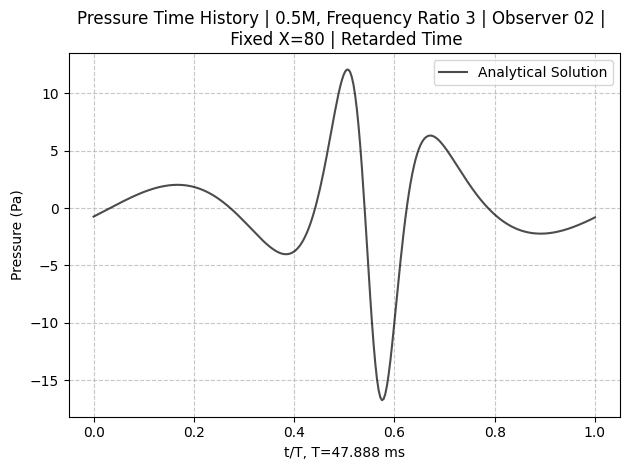

,Time,P_obs
0,0.000000,-0.745758
1,0.000160,-0.672044
2,0.000320,-0.597646
3,0.000480,-0.522652
4,0.000641,-0.447149
...,...,...
295,0.047247,-1.101026
296,0.047407,-1.032034
297,0.047567,-0.961925
298,0.047728,-0.890785


In [13]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio3_xpsweep')
obs_id = ['02']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 80
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []

    FWHPlotter.plot_pressure(
        ana_dataset, 
        ref_col='P_obs',
        title=f'Pressure Time History | 0.5M, Frequency Ratio 3 | Observer {obs} | \n Fixed X={x_fixed} | Retarded Time',
        error_method='l2',
        x_axis='normalised'
    )

ana_dataset.data

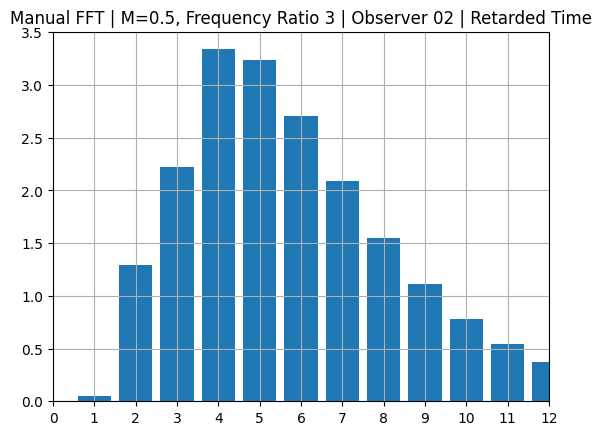

In [14]:
data = ana_dataset.data
time, pressure = data.iloc[:,0], data.iloc[:,1]

fft = np.fft.rfft(pressure)
index = range(len(fft))

fig, ax = plt.subplots()
ax.bar(index, np.abs(fft)/(len(data)) * 2)
ax.set_xlim(0, 12)
ax.grid(True)
ax.set_title("Manual FFT | M=0.5, Frequency Ratio 3 | Observer 02 | Retarded Time")
ax.set_xticks(np.linspace(0,12,13))

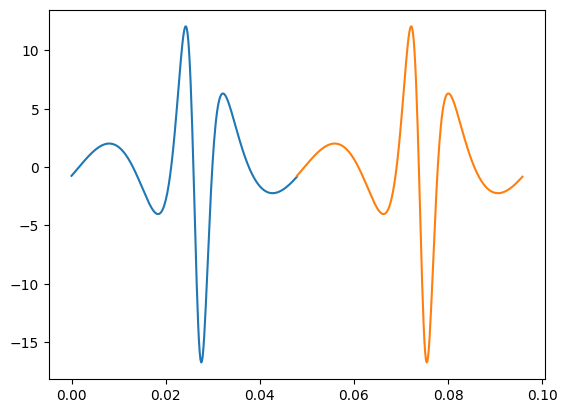

In [10]:
fig, ax = plt.subplots()
ax.plot(ana_dataset.data.iloc[:,0], ana_dataset.data.iloc[:,1])
ax.plot(ana_dataset.data.iloc[:,0] + 0.047888, ana_dataset.data.iloc[:,1])

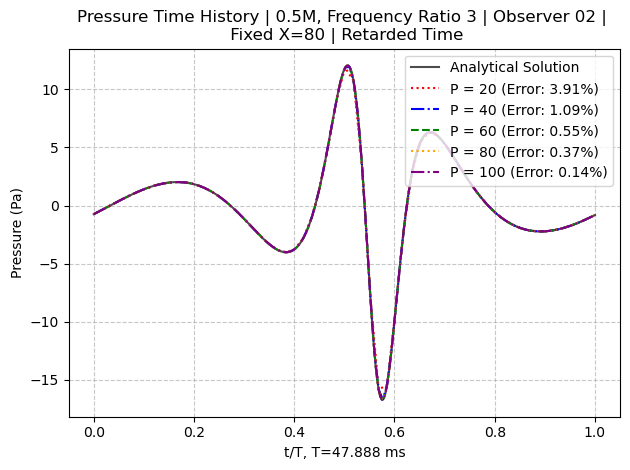

DEBUG: Loaded References: ['obs_01', 'obs_03', 'obs_02']


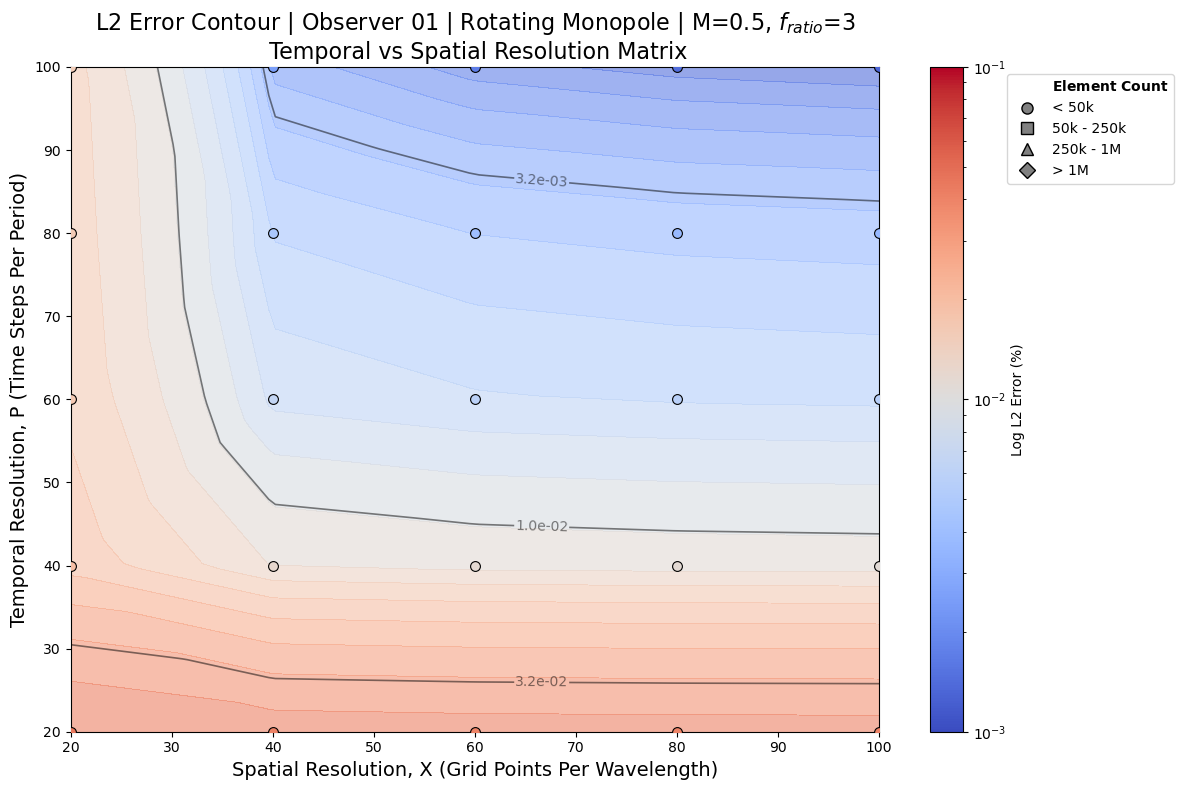

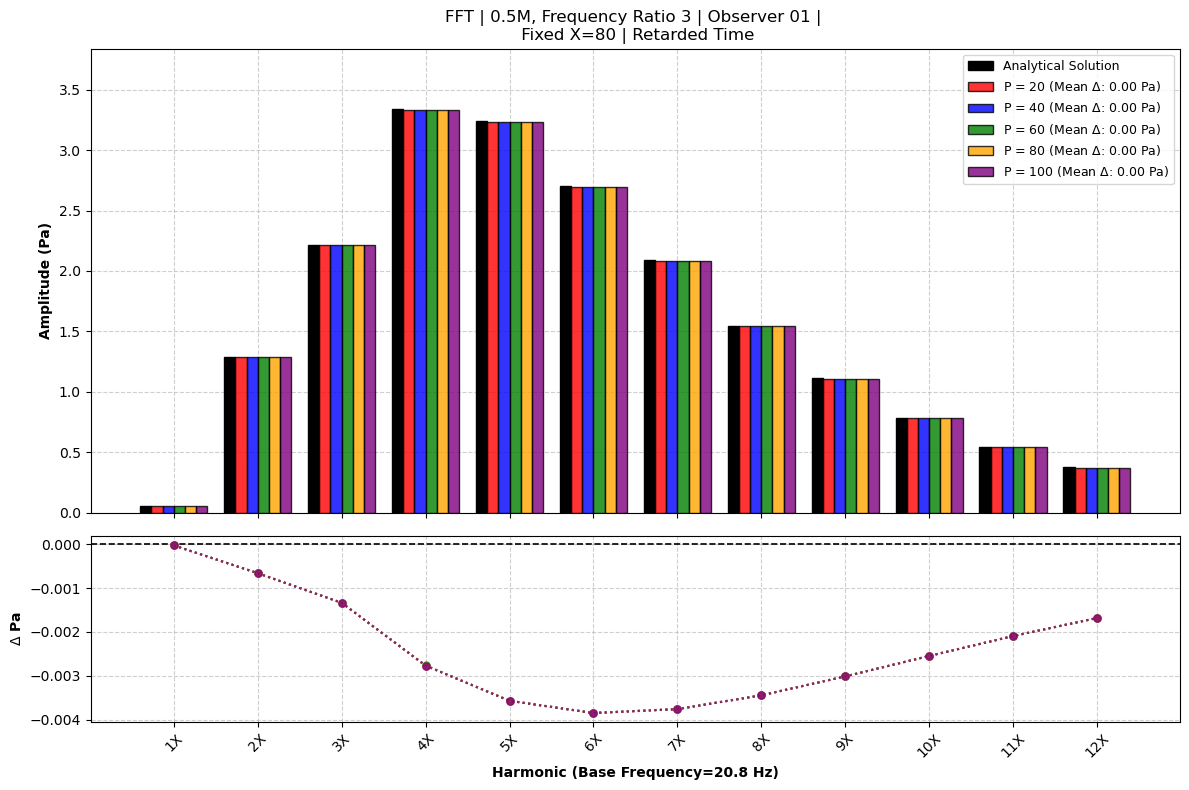

In [3]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio3_xpsweep')
obs_id = ['02']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 80
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'Pressure Time History | 0.5M, Frequency Ratio 3 | Observer {obs} | \n Fixed X={x_fixed} | Retarded Time',
        error_method='l2',
        x_axis='normalised'
    )

# FWHPlotter.plot_directivity(ana_dataset, *target_datasets, labels=dataset_labels, y_axis='spl')

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 62.43
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=3', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )
FWHPlotter.plot_fft_spectrum(
    ana_dataset,
    *target_datasets,
    f_base=FWHDataset.F_SOURCE / 3,
    num_harmonics=12,
    labels=dataset_labels,
    ref_col='P_obs',
    show_error_subplot=True,
    y_axis='pressure',
    window='rectangular',
    title=f'FFT | 0.5M, Frequency Ratio 3 | Observer {obs} | \n Fixed X={x_fixed} | Retarded Time',
)
# FWHPlotter.plot_fft_spectrum(
#     ana_dataset,
#     # *target_datasets,
#     f_base=FWHDataset.F_SOURCE / 3,
#     num_harmonics=12,
#     # labels=dataset_labels,
#     ref_col='P_obs',
#     show_error_subplot=True,
#     title=f'DFT | 0.5M, Frequency Ratio 3 | Observer {obs} | \n Fixed X={x_fixed} | Retarded Time',
# )

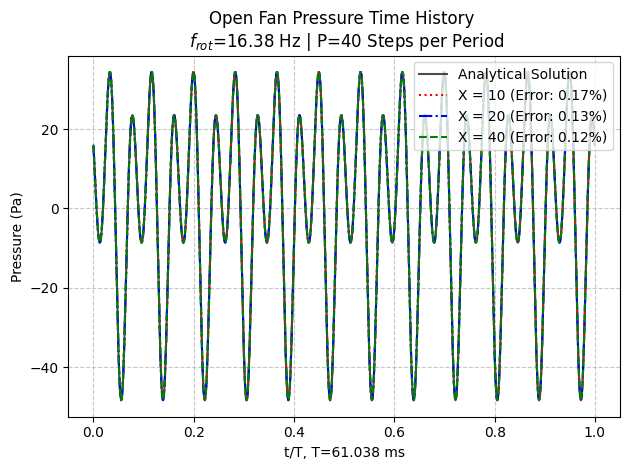

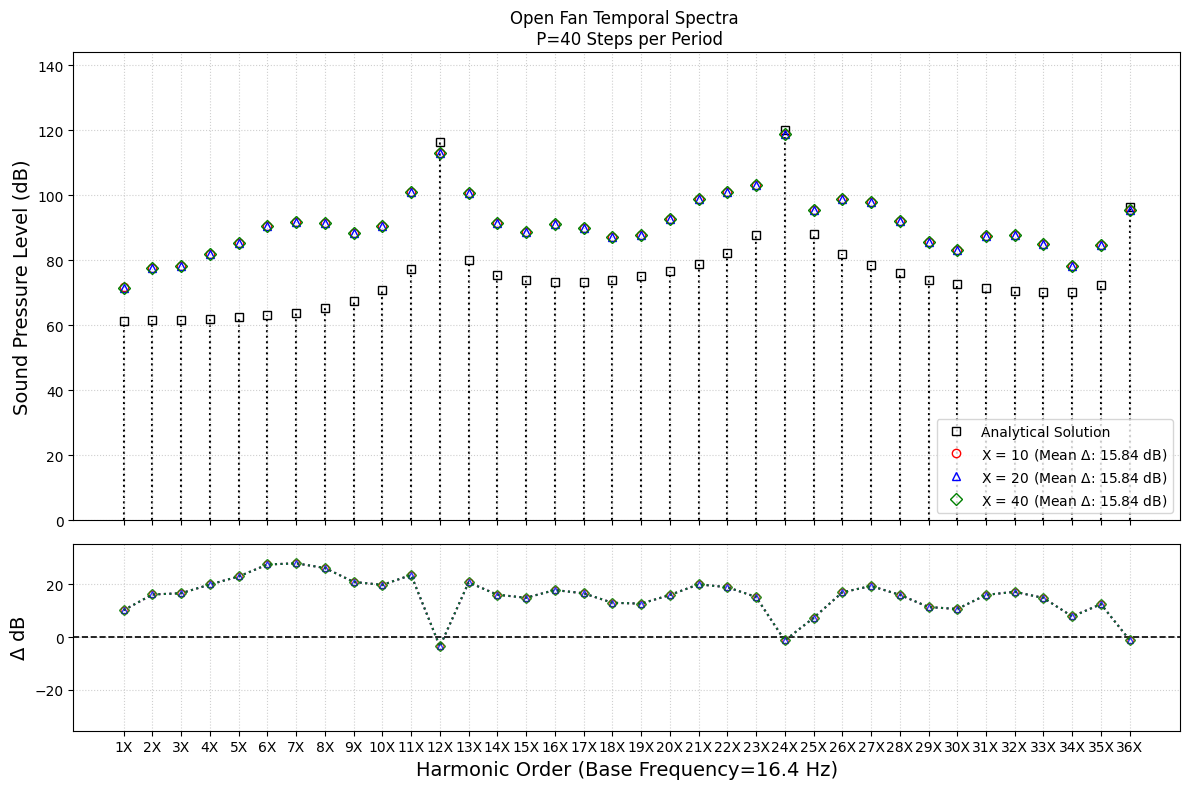

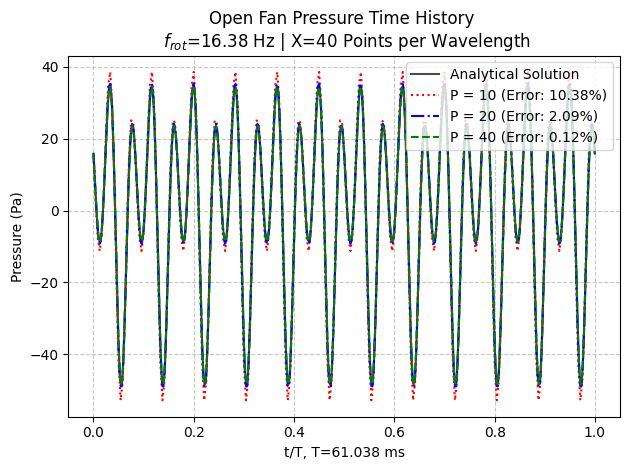

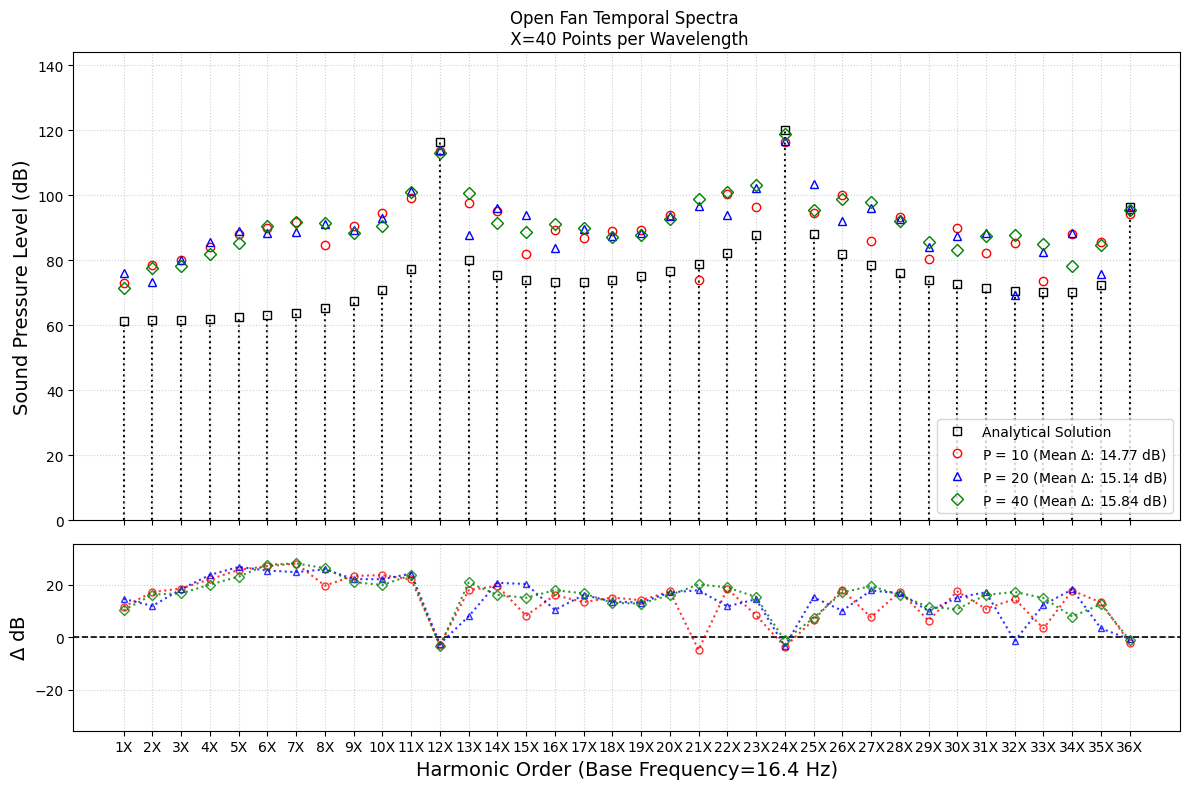

In [9]:
import numpy as np
from pathlib import Path

date = '260902' 
filepath = Path(f'data_{date}/OpenFan_XPSweep/plane_z')
obs_id = '001'

p_test_vals = [10, 20, 40]
x_test_vals = [10, 20, 40]

p_fixed = 40
x_fixed = 40

rotor_speed_rpm = 983 
f_rot = rotor_speed_rpm / 60
T_rot = 1.0 / f_rot

def filter_at_transient(dataset, t_discard):
    """
    Slices off the initial physical propagation delay (e.g., 1 rotation period) 
    from the Advanced Time output and resets the time vector to 0 to align 
    perfectly with the analytical reference.
    """
    mask = dataset.data['Time'] >= t_discard
    dataset.data = dataset.data[mask].copy()
    dataset.data['Time'] -= t_discard
    return dataset

# Load and filter Analytical Baseline
ana_path = filepath / f'analytical_{obs_id}.dat'
if ana_path.exists():
    ana_dataset = FWHDataset(filepath=ana_path)
    # The analytical solution is already clean, but we slice it to match the window length
    ana_dataset = filter_at_transient(ana_dataset, T_rot)
else:
    raise FileNotFoundError(f"Analytical master not found at {ana_path}")

# ==========================================
# 1. SWEEP X (Holding P Constant)
# ==========================================
x_datasets = []
x_labels = []

for x in x_test_vals:
    num_path = filepath / f'P{p_fixed}_X{x}_{obs_id}.dat'
    if num_path.exists():
        ds = FWHDataset(filepath=num_path)
        ds = filter_at_transient(ds, T_rot)
        x_datasets.append(ds)
        x_labels.append(f'X = {x}')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *x_datasets, 
    ref_col='P_obs',
    labels=x_labels,
    title=f'Open Fan Pressure Time History \n $f_{{rot}}$={f_rot:.2f} Hz | P={p_fixed} Steps per Period',
    error_method='l2',
    x_axis='normalised',
    time_method='AT',
    time_period=T_rot
)

# Plot temporal harmonics (using f_rot as base to map Engine Orders up to EO 36)
FWHPlotter.plot_fft_spectrum(
    ana_dataset, *x_datasets, labels=x_labels, f_base=f_rot, num_harmonics=36, 
    ref_col='P_obs', show_error_subplot=True, y_axis='spl', window='rectangular',
    title=f'Open Fan Temporal Spectra \n P={p_fixed} Steps per Period'
)

# ==========================================
# 2. SWEEP P (Holding X Constant)
# ==========================================
p_datasets = []
p_labels = []

for p in p_test_vals:
    num_path = filepath / f'P{p}_X{x_fixed}_{obs_id}.dat'
    if num_path.exists():
        ds = FWHDataset(filepath=num_path)
        ds = filter_at_transient(ds, T_rot)
        p_datasets.append(ds)
        p_labels.append(f'P = {p}')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *p_datasets, 
    ref_col='P_obs',
    labels=p_labels,
    title=f'Open Fan Pressure Time History \n $f_{{rot}}$={f_rot:.2f} Hz | X={x_fixed} Points per Wavelength',
    error_method='l2',
    x_axis='normalised',
    time_method='AT',
    time_period=T_rot
)

FWHPlotter.plot_fft_spectrum(
    ana_dataset, *p_datasets, labels=p_labels, f_base=f_rot, num_harmonics=36, 
    ref_col='P_obs', show_error_subplot=True, y_axis='spl', window='rectangular',
    title=f'Open Fan Temporal Spectra \n X={x_fixed} Points per Wavelength'
)

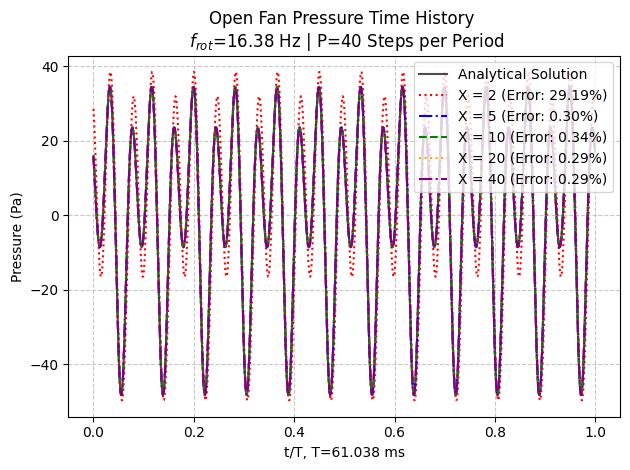

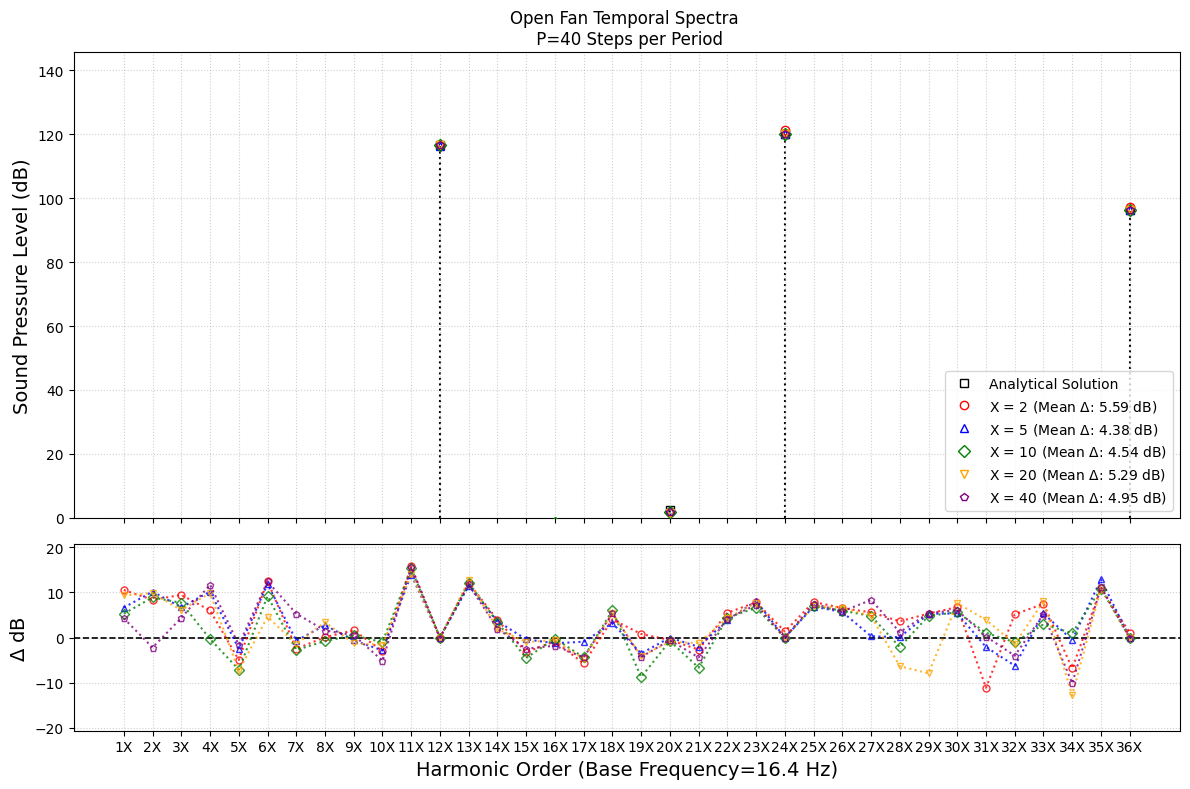

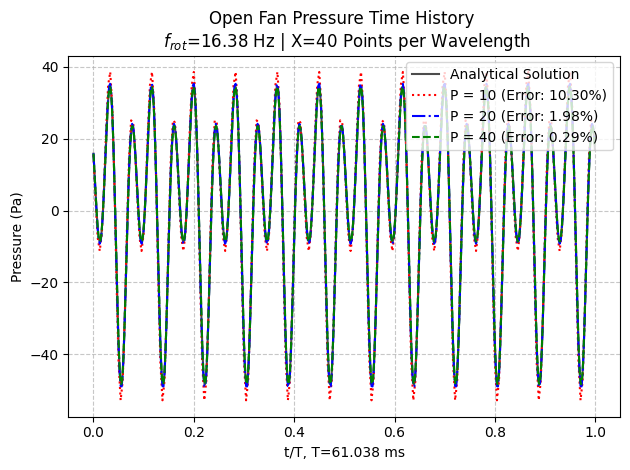

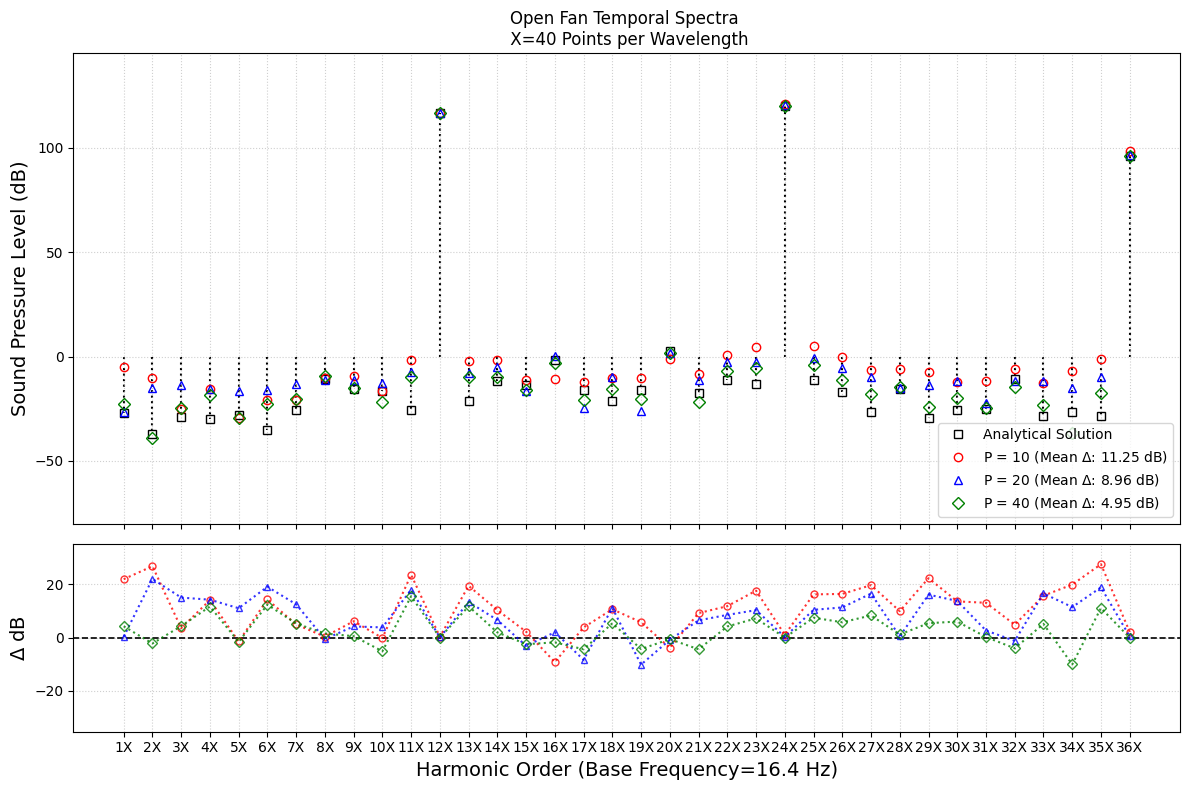

DEBUG: Loaded References: []
No data found for Observer 001. Skipping.


In [23]:
import numpy as np
from pathlib import Path

date = '260902' 
filepath = Path(f'data_{date}/OpenFan_XPSweep/plane_z')
obs_id = '001'

p_test_vals = [10, 20, 40]
x_test_vals = [2, 5, 10, 20, 40]

p_fixed = 40
x_fixed = 40

rotor_speed_rpm = 983 
f_rot = rotor_speed_rpm / 60
T_rot = 1.0 / f_rot

def filter_at_transient(dataset, T_period):
    """
    Bypasses the Advanced Time transient AND the floating-point truncation 
    by extracting exactly one pristine mathematical period using integer indices.
    """
    df = dataset.data
    dt = df['Time'].iloc[1] - df['Time'].iloc[0]
    
    # Calculate exactly how many points make up one rotation
    N_period = int(np.round(T_period / dt))
    
    # Skip the first period (transient delay) and grab exactly the second period
    start_idx = N_period
    end_idx = start_idx + N_period
    
    # Slice the pristine array
    dataset.data = df.iloc[start_idx:end_idx].copy()
    
    # Reset time to start at 0 so analytical and numerical align perfectly on the plot
    t_start = dataset.data['Time'].iloc[0]
    dataset.data['Time'] -= t_start
    
    return dataset

# Load and filter Analytical Baseline
ana_path = filepath / f'analytical_{obs_id}.dat'
if ana_path.exists():
    ana_dataset = FWHDataset(filepath=ana_path)
    ana_dataset = filter_at_transient(ana_dataset, T_rot)
else:
    raise FileNotFoundError(f"Analytical master not found at {ana_path}")

# ==========================================
# 1. SWEEP X (Holding P Constant)
# ==========================================
x_datasets = []
x_labels = []

for x in x_test_vals:
    num_path = filepath / f'P{p_fixed}_X{x}_{obs_id}.dat'
    if num_path.exists():
        ds = FWHDataset(filepath=num_path)
        ds = filter_at_transient(ds, T_rot)
        x_datasets.append(ds)
        x_labels.append(f'X = {x}')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *x_datasets, 
    ref_col='P_obs',
    labels=x_labels,
    title=f'Open Fan Pressure Time History \n $f_{{rot}}$={f_rot:.2f} Hz | P={p_fixed} Steps per Period',
    error_method='l2',
    x_axis='normalised',
    time_method='AT',
    time_period=T_rot
)

# Plot temporal harmonics (using f_rot as base to map Engine Orders up to EO 36)
FWHPlotter.plot_fft_spectrum(
    ana_dataset, *x_datasets, labels=x_labels, f_base=f_rot, num_harmonics=36, 
    ref_col='P_obs', show_error_subplot=True, y_axis='spl', window='rectangular',
    title=f'Open Fan Temporal Spectra \n P={p_fixed} Steps per Period'
)

# ==========================================
# 2. SWEEP P (Holding X Constant)
# ==========================================
p_datasets = []
p_labels = []

for p in p_test_vals:
    num_path = filepath / f'P{p}_X{x_fixed}_{obs_id}.dat'
    if num_path.exists():
        ds = FWHDataset(filepath=num_path)
        ds = filter_at_transient(ds, T_rot)
        p_datasets.append(ds)
        p_labels.append(f'P = {p}')

FWHPlotter.plot_pressure(
    ana_dataset, 
    *p_datasets, 
    ref_col='P_obs',
    labels=p_labels,
    title=f'Open Fan Pressure Time History \n $f_{{rot}}$={f_rot:.2f} Hz | X={x_fixed} Points per Wavelength',
    error_method='l2',
    x_axis='normalised',
    time_method='AT',
    time_period=T_rot
)

FWHPlotter.plot_fft_spectrum(
    ana_dataset, *p_datasets, labels=p_labels, f_base=f_rot, num_harmonics=36, 
    ref_col='P_obs', show_error_subplot=True, y_axis='spl', window='rectangular',
    title=f'Open Fan Temporal Spectra \n X={x_fixed} Points per Wavelength',
    bottom_y=-80
)

FWHDataset.R = 1.3 * 3.96 / 2
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 2 * 12 * 983 / 60
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['001']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=rf'Open Fan Sensitivity Study', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3                
    )

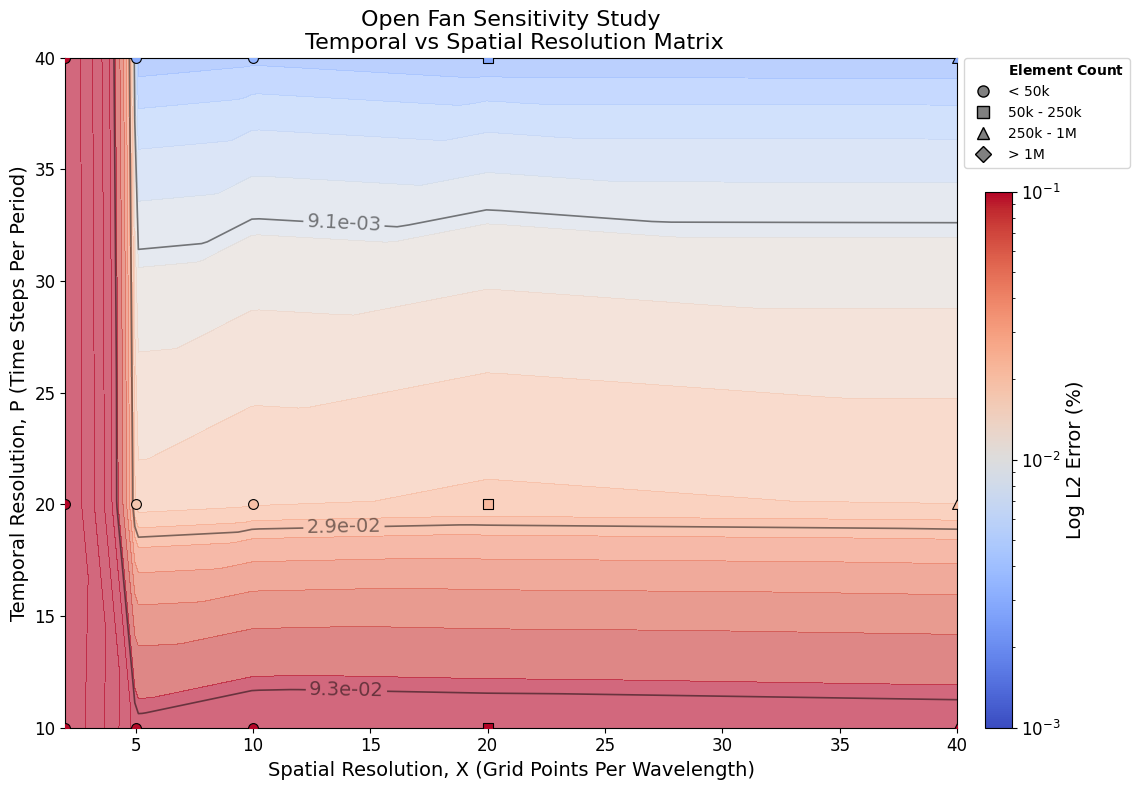

In [24]:
import re
import numpy as np
from pathlib import Path

# 1. Preamble Setup (Required for element count calculations)
FWHDataset.R = 1.3 * 3.96 / 2
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 2 * 12 * 983 / 60
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

filepath = Path(f'data_260902/OpenFan_XPSweep/plane_z')
obs = '001'

# Hard-lock the true physical kinematics
rotor_speed_rpm = 983 
f_rot = rotor_speed_rpm / 60
T_rot = 1.0 / f_rot

def trim_to_second_period(dataset):
    """
    Bypasses the Advanced Time transient AND the floating-point truncation 
    by extracting exactly one pristine mathematical period.
    """
    df = dataset.data
    dt = df['Time'].iloc[1] - df['Time'].iloc[0]
    
    # Calculate exactly how many points make up one rotation
    N_period = int(np.round(T_rot / dt))
    
    # Isolate exactly the second period
    dataset.data = df.iloc[N_period : 2*N_period].copy()
    
    # Reset timeline to 0
    t_start = dataset.data['Time'].iloc[0]
    dataset.data['Time'] -= t_start
    return dataset

# ==========================================
# 2. Process Analytical Baseline
# ==========================================
ana_path = filepath / f'analytical_{obs}.dat'
ana_dataset = FWHDataset(filepath=ana_path)
ana_dataset = trim_to_second_period(ana_dataset)

# ==========================================
# 3. Custom Batch Parser & Error Calculator
# ==========================================
observer_data = []

# Search for all numerical files for this specific observer
for num_path in filepath.glob(f'P*_X*_{obs}.dat'):
    
    match = re.search(r'P(\d+)_X(\d+)', num_path.name)
    if not match:
        continue
        
    p_val = int(match.group(1))
    x_val = int(match.group(2))
    
    num_dataset = FWHDataset(filepath=num_path)
    num_dataset = trim_to_second_period(num_dataset)
    
    # Calculate the L2 error strictly on the pristine second period
    l2_err = num_dataset.l2_error(ana_dataset, col='P_obs')
    
    # THE FIX: Explicitly calculate grid elements to bypass the NoneType error.
    # Matches the n**2 logic from your auto_test.py generator.
    dx = FWHDataset.LAMBDA_SOURCE / x_val
    n_grid = int(np.round((2 * np.pi * FWHDataset.R) / dx))
    elems = n_grid ** 2  
    
    observer_data.append({
        'dataset': num_dataset,
        'observer': obs,
        'P': p_val,
        'X': x_val,
        'elements': elems,
        'error': l2_err
    })

if not observer_data:
    print(f"No valid numerical data found for Observer {obs}. Check filename formatting.")
else:
    # ==========================================
    # 4. Generate PX Contour Plot
    # ==========================================
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'Open Fan Sensitivity Study', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, 
        vmin=1e-3   
    )

In [5]:
# date = '260825'
# filepath = Path(f'data_{date}/M0.5_fratio1')
# obs_id = ['01']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================


# x_fixed = 100
# p_test_vals = [20, 40, 100]

# f_base = 0.5 * 340 / (1.3 * 2 * np.pi)
# T_fund = 1.0 / f_base
# t_start = 1 * T_fund
# t_end = 2 * T_fund

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)
#     ana_mask = (ana_dataset.data['Time'] >= t_start) & (ana_dataset.data['Time'] <= t_end)
#     ana_dataset.data = ana_dataset.data[ana_mask]

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             ds = FWHDataset(filepath=num_path)
#             num_mask = (ds.data['Time'] >= t_start) & (ds.data['Time'] <= t_end)
#             ds.data = ds.data[num_mask]
            
#             target_datasets.append(ds)
#             dataset_labels.append(f'P = {p}')

# FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 1 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
#         error_method='l2',
#         x_axis='normalised',
#         time_method='AT',
#         time_period=T_fund
#     )

# data = ana_dataset.data
# time, pressure = data.iloc[:,0], data.iloc[:,1]

# fft = np.fft.rfft(pressure)
# index = range(len(fft))

# fig, ax = plt.subplots()
# ax.bar(index, np.abs(fft)/(len(data)) * 2)
# ax.set_xlim(0, 12)
# ax.set_xticks(np.linspace(0,12,13))
# ax.set_title("Manual FFT | M=0.5, Frequency Ratio 1 | Advanced Time")

# FWHPlotter.plot_fft_spectrum(
#     ana_dataset,
#     *target_datasets,
#     f_base=f_base,
#     num_harmonics=12,
#     labels=dataset_labels,
#     ref_col='P_obs',
#     show_error_subplot=False,
#     y_axis='pressure',
#     window='rectangular',
#     title=f'FFT | 0.5M, Frequency Ratio 1 | Observer {obs} | \n Fixed X={x_fixed} | Advanced Time',
# )



In [7]:
# date = '260825'
# filepath = Path(f'data_{date}/M0.5_fratio2')
# obs_id = ['01']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================


# x_fixed = 100
# p_test_vals = [20, 40, 100]

# f_base = 0.5 * 340 / (1.3 * 2 * np.pi)
# T_fund = 1.0 / f_base
# t_start = 1 * T_fund
# t_end = 2 * T_fund

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)
#     ana_mask = (ana_dataset.data['Time'] >= t_start) & (ana_dataset.data['Time'] <= t_end)
#     ana_dataset.data = ana_dataset.data[ana_mask]

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             ds = FWHDataset(filepath=num_path)
#             num_mask = (ds.data['Time'] >= t_start) & (ds.data['Time'] <= t_end)
#             ds.data = ds.data[num_mask]
            
#             target_datasets.append(ds)
#             dataset_labels.append(f'P = {p}')

# FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 2 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
#         error_method='l2',
#         x_axis='normalised',
#         time_method='AT',
#         time_period=T_fund
#     )

# data = ana_dataset.data
# time, pressure = data.iloc[:,0], data.iloc[:,1]

# fft = np.fft.rfft(pressure)
# index = range(len(fft))

# fig, ax = plt.subplots()
# ax.grid(True)
# ax.bar(index, np.abs(fft)/(len(data)) * 2)
# ax.set_xlim(0, 12)
# ax.set_xticks(np.linspace(0,12,13))
# ax.set_title('Manual FFT | 0.5M, Frequency Ratio 2 | Advanced Time')

# FWHPlotter.plot_fft_spectrum(
#     ana_dataset,
#     *target_datasets,
#     f_base=f_base,
#     num_harmonics=12,
#     labels=dataset_labels,
#     ref_col='P_obs',
#     show_error_subplot=False,
#     y_axis='pressure',
#     window='rectangular',
#     title=f'FFT | 0.5M, Frequency Ratio 2 | Observer {obs} | \n Fixed X={x_fixed} | Advanced Time',
# )



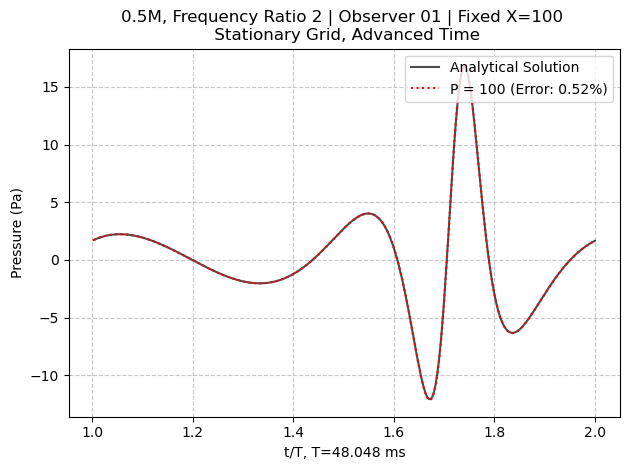

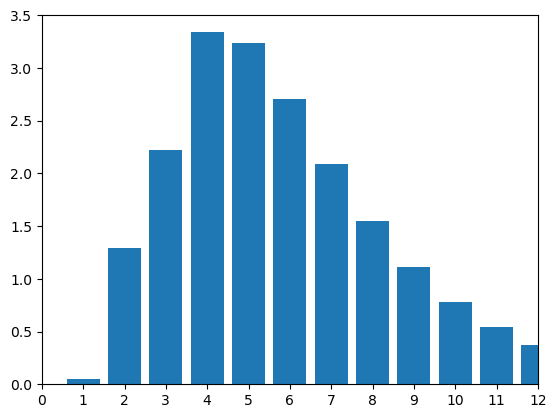

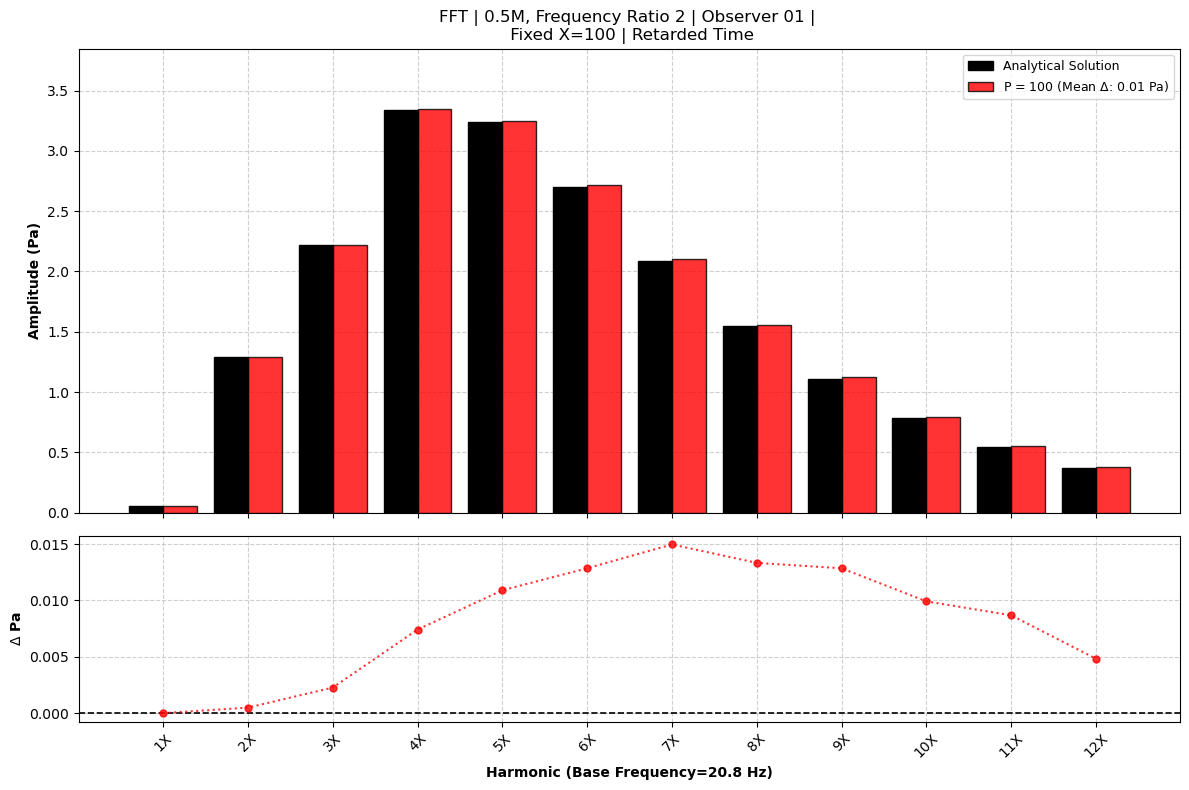

In [8]:
date = '260825'
filepath = Path(f'data_{date}/M0.5_fratio3')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================

x_fixed = 100
p_test_vals = [20, 40, 100]

f_base = 0.5 * 340 / (1.3 * 2 * np.pi)
T_fund = 1.0 / f_base
t_start = 1 * T_fund
t_end = 2 * T_fund

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)
    ana_mask = (ana_dataset.data['Time'] >= t_start) & (ana_dataset.data['Time'] <= t_end)
    ana_dataset.data = ana_dataset.data[ana_mask]

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            ds = FWHDataset(filepath=num_path)
            num_mask = (ds.data['Time'] >= t_start) & (ds.data['Time'] <= t_end)
            ds.data = ds.data[num_mask]
            
            target_datasets.append(ds)
            dataset_labels.append(f'P = {p}')

FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.5M, Frequency Ratio 2 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
        error_method='l2',
        x_axis='normalised',
        time_method='AT',
        time_period=T_fund
    )

data = ana_dataset.data
time, pressure = data.iloc[:,0], data.iloc[:,1]

fft = np.fft.rfft(pressure)
index = range(len(fft))

fig, ax = plt.subplots()
ax.bar(index, np.abs(fft)/(len(data)) * 2)
ax.set_xlim(0, 12)
ax.set_xticks(np.linspace(0,12,13))

FWHPlotter.plot_fft_spectrum(
    ana_dataset,
    *target_datasets,
    f_base=f_base,
    num_harmonics=12,
    labels=dataset_labels,
    ref_col='P_obs',
    show_error_subplot=True,
    y_axis='pressure',
    window='rectangular',
    title=f'FFT | 0.5M, Frequency Ratio 2 | Observer {obs} | \n Fixed X={x_fixed} | Retarded Time',
)



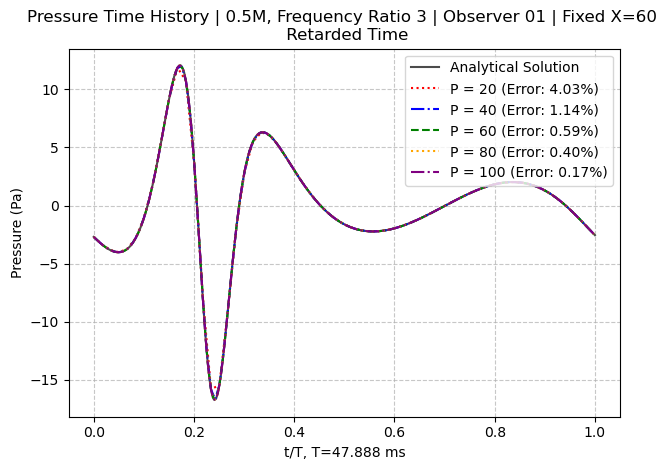

DEBUG: Loaded References: ['obs_01', 'obs_03', 'obs_02']


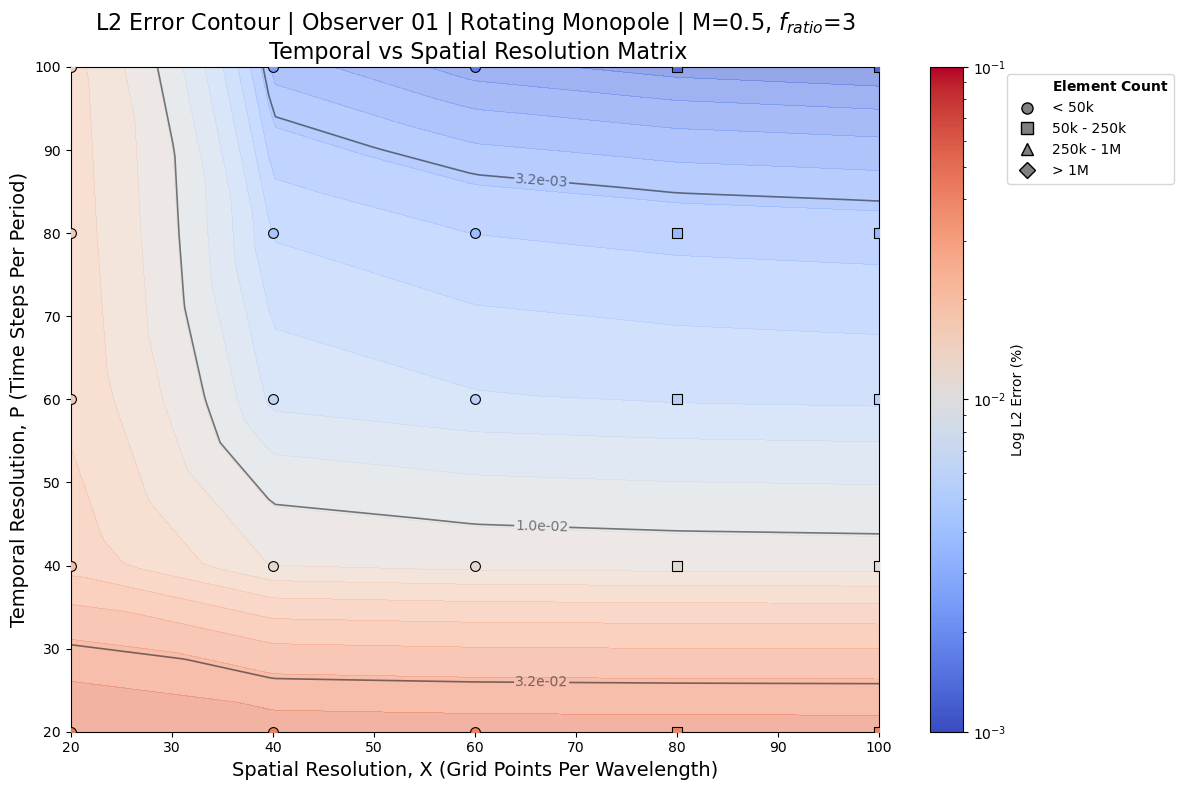

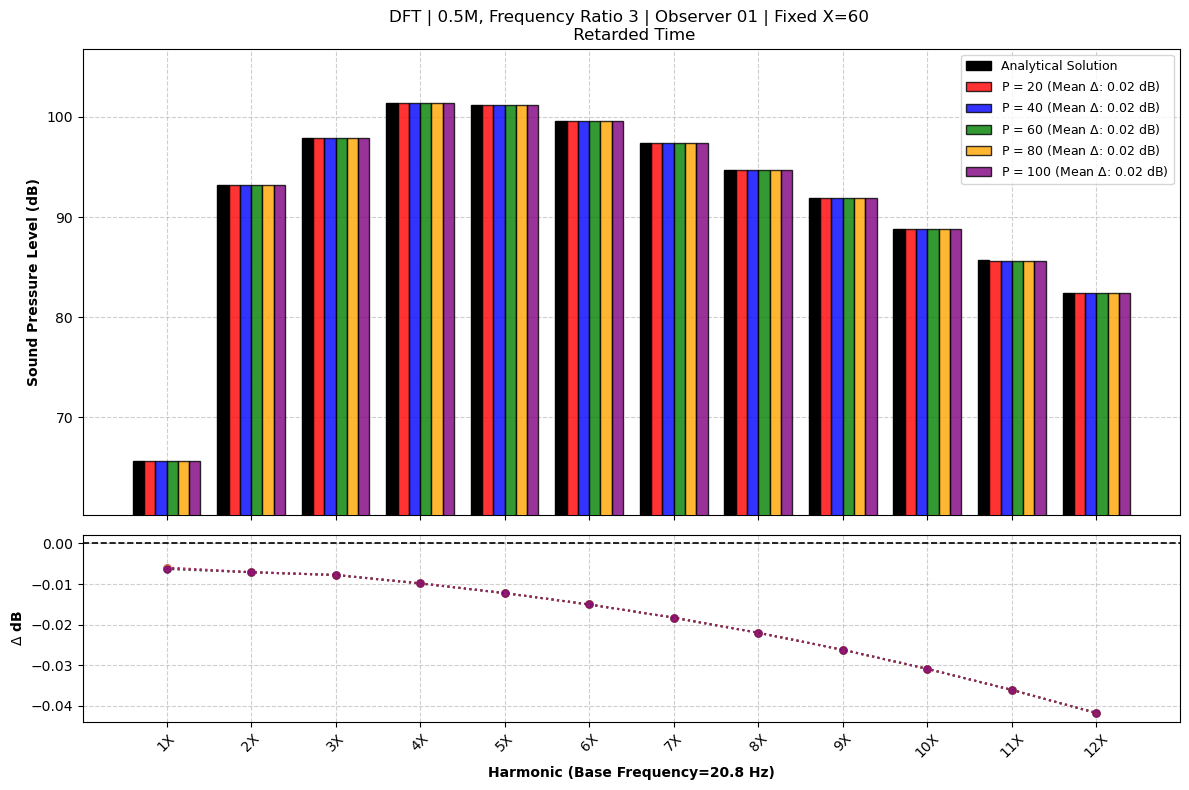

In [13]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio3_xpsweep')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 60
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'Pressure Time History | 0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Retarded Time',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 104
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=3', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )

FWHPlotter.plot_fft_spectrum(
    ana_dataset,
    *target_datasets,
    f_base=FWHDataset.F_SOURCE / 5,
    num_harmonics=12,
    labels=dataset_labels,
    ref_col='P_obs',
    show_error_subplot=True,
    title=f'DFT | 0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Retarded Time',
    window='rectangular'
)

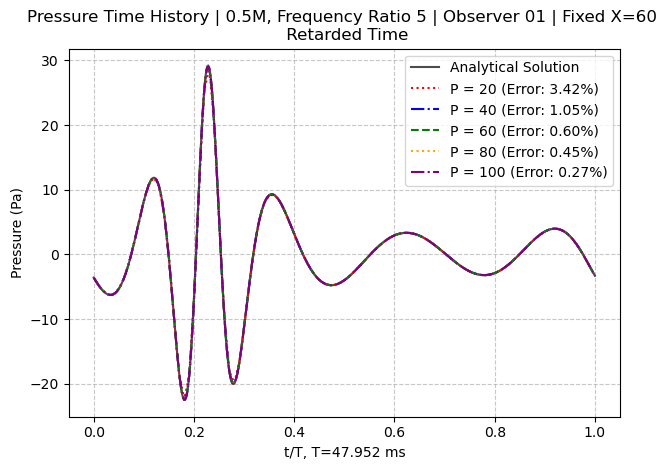

DEBUG: Loaded References: ['obs_01', 'obs_03', 'obs_02']


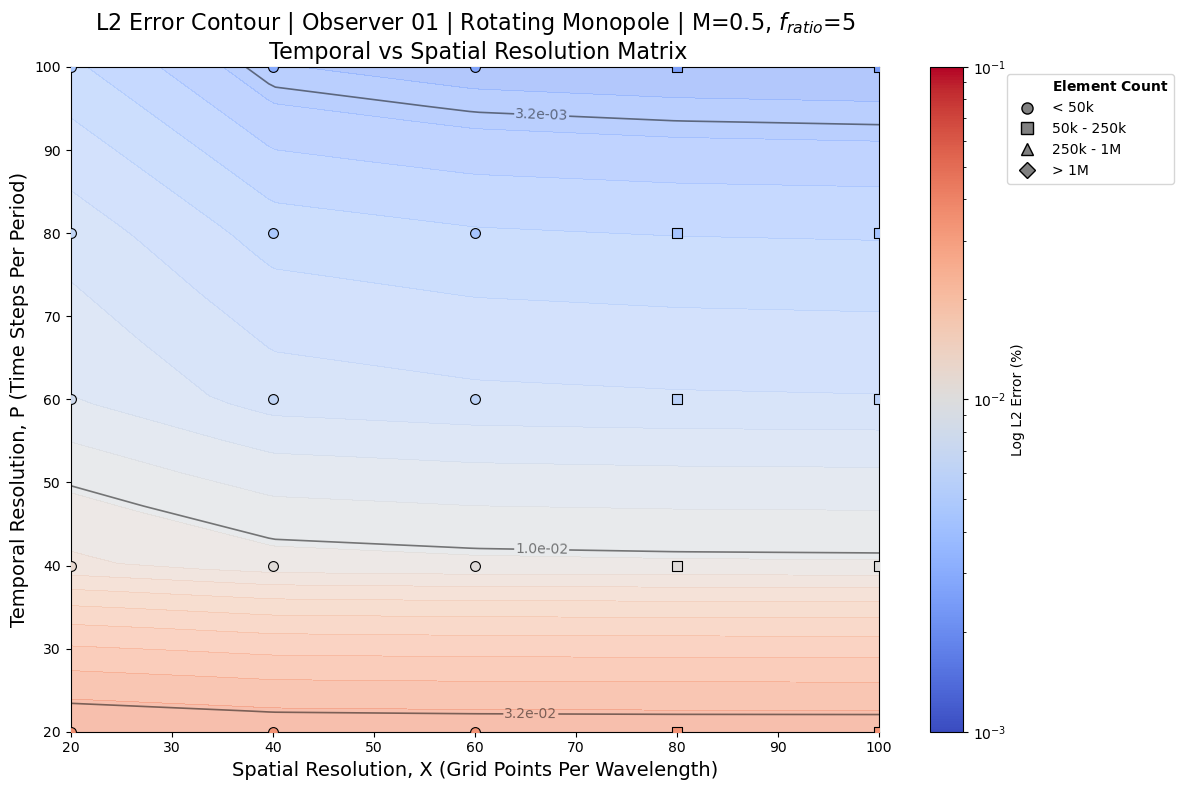

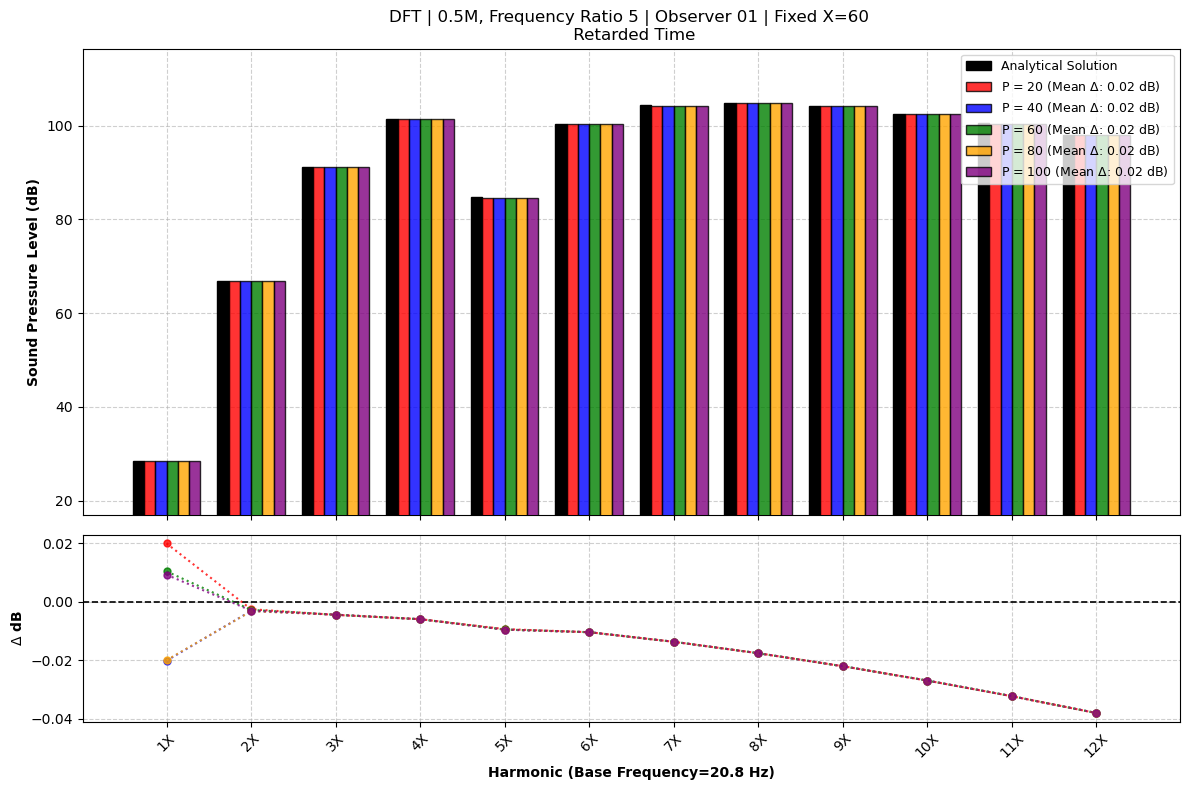

In [9]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio5_xpsweep')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 60
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'Pressure Time History | 0.5M, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Retarded Time',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 104
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=5', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )

FWHPlotter.plot_fft_spectrum(
    ana_dataset,
    *target_datasets,
    f_base=FWHDataset.F_SOURCE / 5,
    num_harmonics=12,
    labels=dataset_labels,
    ref_col='P_obs',
    show_error_subplot=True,
    title=f'DFT | 0.5M, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Retarded Time',
    window='rectangular'
)

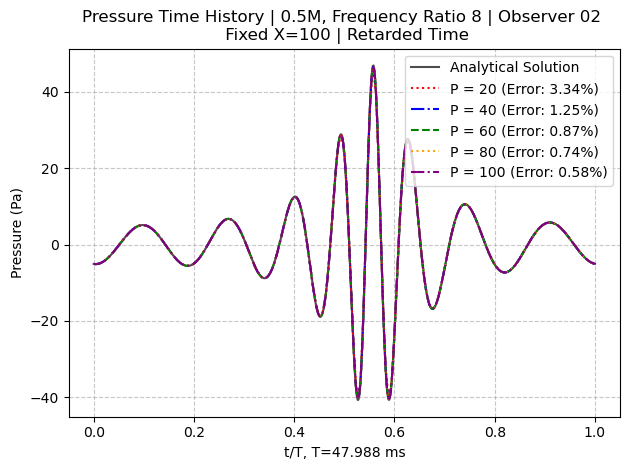

DEBUG: Loaded References: ['obs_01', 'obs_03', 'obs_02']


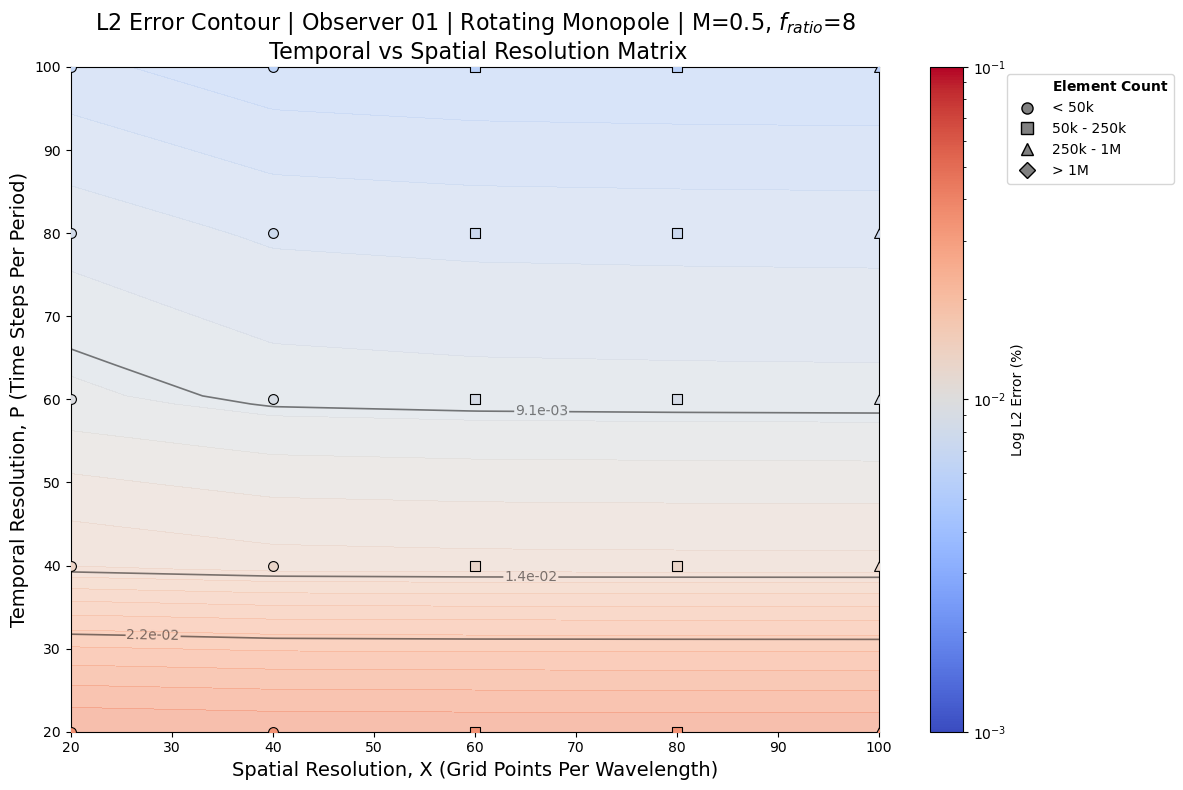

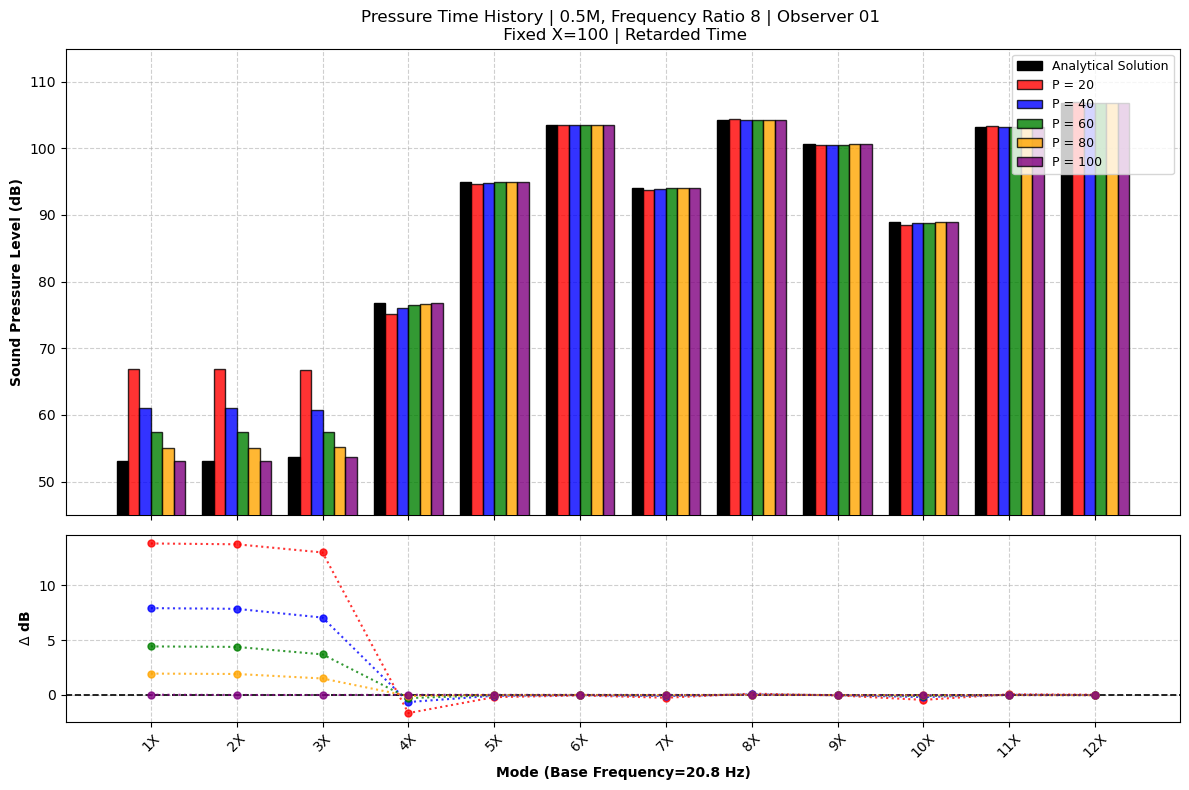

In [10]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio8_xpsweep')
obs_id = ['02']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 100
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'Pressure Time History | 0.5M, Frequency Ratio 8 | Observer {obs} \n Fixed X={x_fixed} | Retarded Time',
        error_method='l2',
        x_axis='normalised'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 166.5
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=8', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )

FWHPlotter.plot_dft_spectrum(
    ana_dataset,
    *target_datasets,
    f_base=FWHDataset.F_SOURCE / 8,
    num_harmonics=12,
    labels=dataset_labels,
    ref_col='P_obs',
    show_error_subplot=True,
    title=f'Pressure Time History | 0.5M, Frequency Ratio 8 | Observer {obs} \n Fixed X={x_fixed} | Retarded Time'
)

In [59]:
# date = '260817'
# filepath = Path(f'data_{date}/M0.5_fratio12_xpsweep_AT')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 100
# p_test_vals = [100]

# r = 6.725
# c = 340.0
# t_start = 0.025


# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)
#     ana_dataset.data = ana_dataset.data[ana_dataset.data['Time'] >= t_start]

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             ds = FWHDataset(filepath=num_path)
#             ds.data = ds.data[ds.data['Time'] >= t_start]
#             # target_datasets.append(FWHDataset(filepath=num_path))
#             target_datasets.append(ds)
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 12 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Advanced Time',
#         error_method='l2',
#         x_axis='normalised',
#         time_method='RT'
#     )


In [60]:
# date = '260817'
# filepath = Path(f'data_{date}/M0.5_fratio12_xpsweep_AT')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 100
# p_test_vals = [40, 100]

# r = 6.725
# c = 340.0
# t_start = 0.025


# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)
#     ana_dataset.data = ana_dataset.data[ana_dataset.data['Time'] >= t_start]

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             ds = FWHDataset(filepath=num_path)
#             ds.data = ds.data[ds.data['Time'] >= t_start]
#             # target_datasets.append(FWHDataset(filepath=num_path))
#             target_datasets.append(ds)
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 12 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Advanced Time (Filtered)',
#         error_method='l2',
#         x_axis='normalised',
#         time_method='AT'
#     )


In [58]:
# date = '260817'
# filepath = Path(f'data_{date}/M0.5_fratio12_xpsweep_3rot_AT')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 100
# p_test_vals = [20, 40, 100]

# r = 6.725
# c = 340.0
# t_start = 0.025


# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)
#     # ana_dataset.data = ana_dataset.data[ana_dataset.data['Time'] >= t_start]

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             # ds = FWHDataset(filepath=num_path)
#             # ds.data = ds.data[ds.data['Time'] >= t_start]
#             target_datasets.append(FWHDataset(filepath=num_path))
#             # target_datasets.append(ds)
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 12 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Advanced Time',
#         error_method='l2',
#         x_axis='normalised',
#         time_method='RT'
#     )


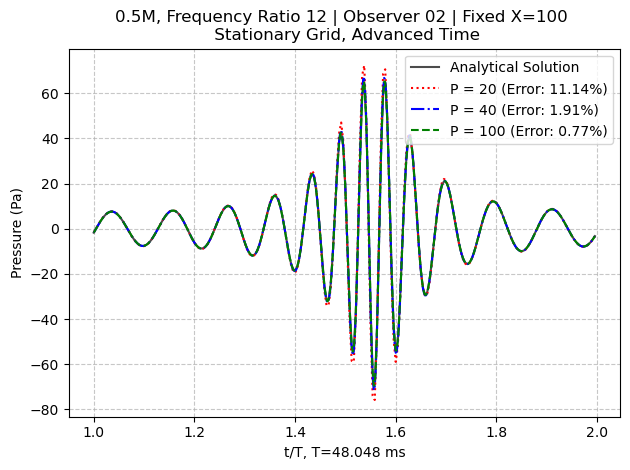

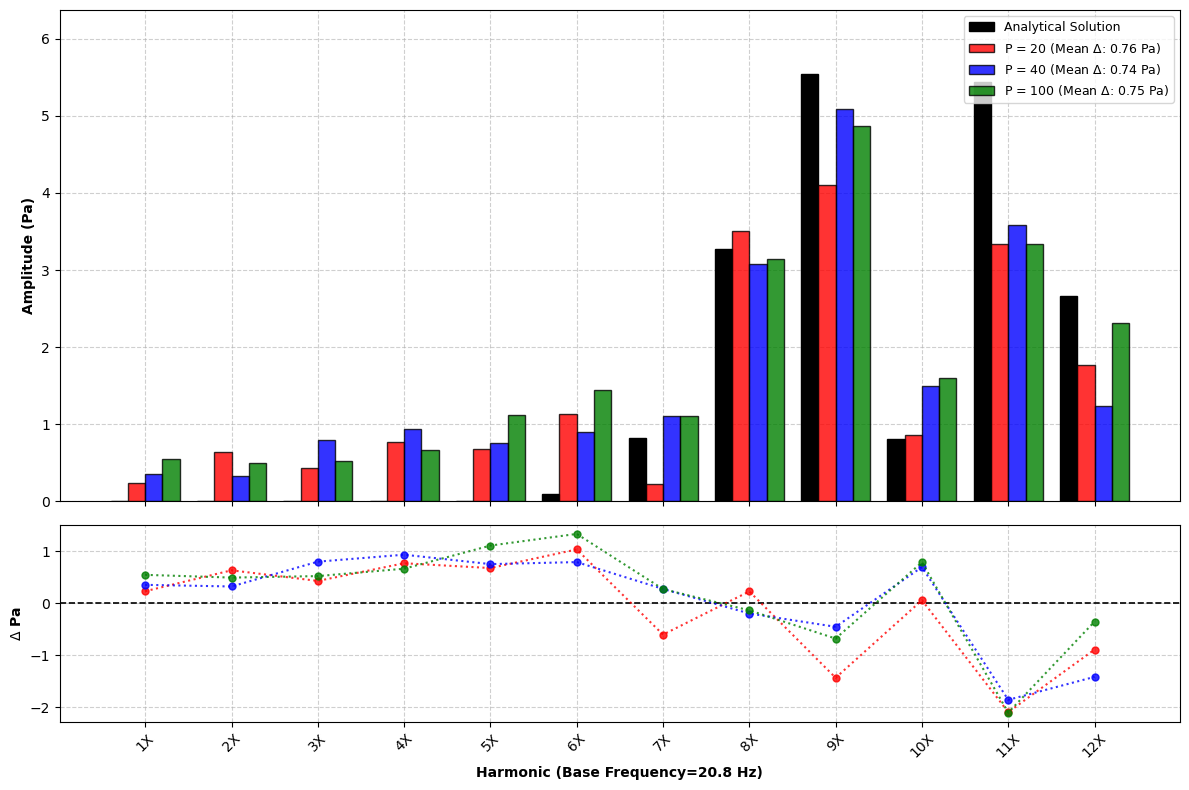

In [28]:
date = '260817'
filepath = Path(f'data_{date}/M0.5_fratio12_xpsweep_3rot_AT')
obs_id = ['02']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 100
p_test_vals = [20, 40, 100]

f_base = 0.5 * 340 / (1.3 * 2 * np.pi)
T_fund = 1.0 / f_base
t_start = 1 * T_fund
t_end = 10 * T_fund

# r = 6.725
# # c = 340.0
# t_start = 0.025


for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)
    ana_mask = (ana_dataset.data['Time'] >= t_start) & (ana_dataset.data['Time'] <= t_end)
    ana_dataset.data = ana_dataset.data[ana_mask]

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            ds = FWHDataset(filepath=num_path)
            num_mask = (ds.data['Time'] >= t_start) & (ds.data['Time'] <= t_end)
            ds.data = ds.data[num_mask]
            
            target_datasets.append(ds)
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.5M, Frequency Ratio 12 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
        error_method='l2',
        x_axis='normalised',
        time_method='AT',
        time_period=T_fund
    )


    FWHPlotter.plot_fft_spectrum(
        ana_dataset,
        *target_datasets,
        f_base=f_base,
        num_harmonics=12,
        labels=dataset_labels,
        t_start=t_start,
        t_end=t_end,
        ref_col='P_obs',
        show_error_subplot=True,
        window='rectangle',
        y_axis='pressure'
    )

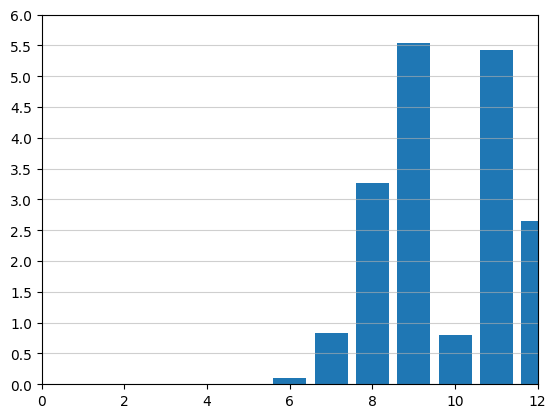

In [4]:
data = ana_dataset.data
time, pressure = data.iloc[:,0], data.iloc[:,1]

fft = np.fft.rfft(pressure)
index = range(len(fft))

fig, ax = plt.subplots()
ax.bar(index, np.abs(fft)/(len(data)) * 2)
ax.set_xlim(0, 12)
ax.set_yticks(np.linspace(0,6,13))
ax.set_ylim(0, 6)
ax.grid(True, axis='y', alpha=0.6)

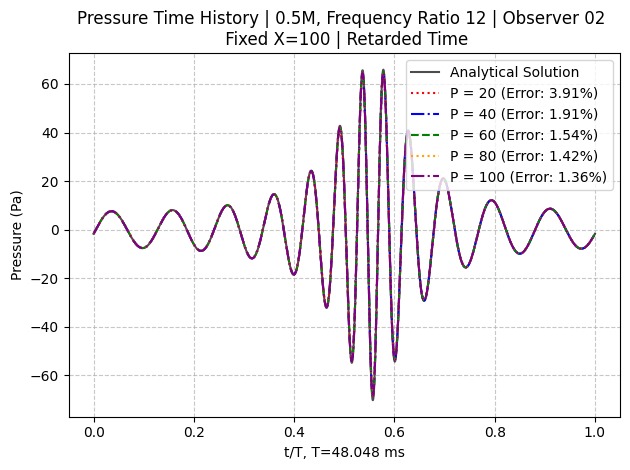

DEBUG: Loaded References: ['obs_02', 'obs_03', 'obs_01']


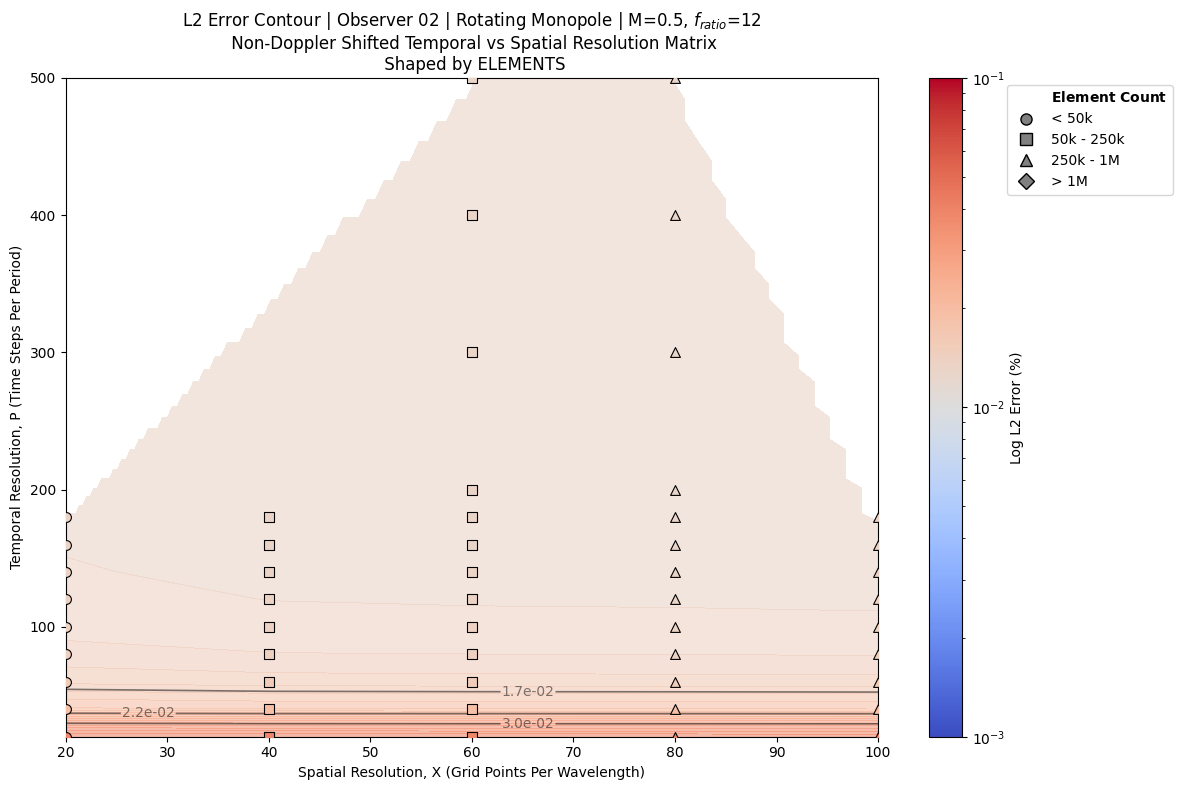

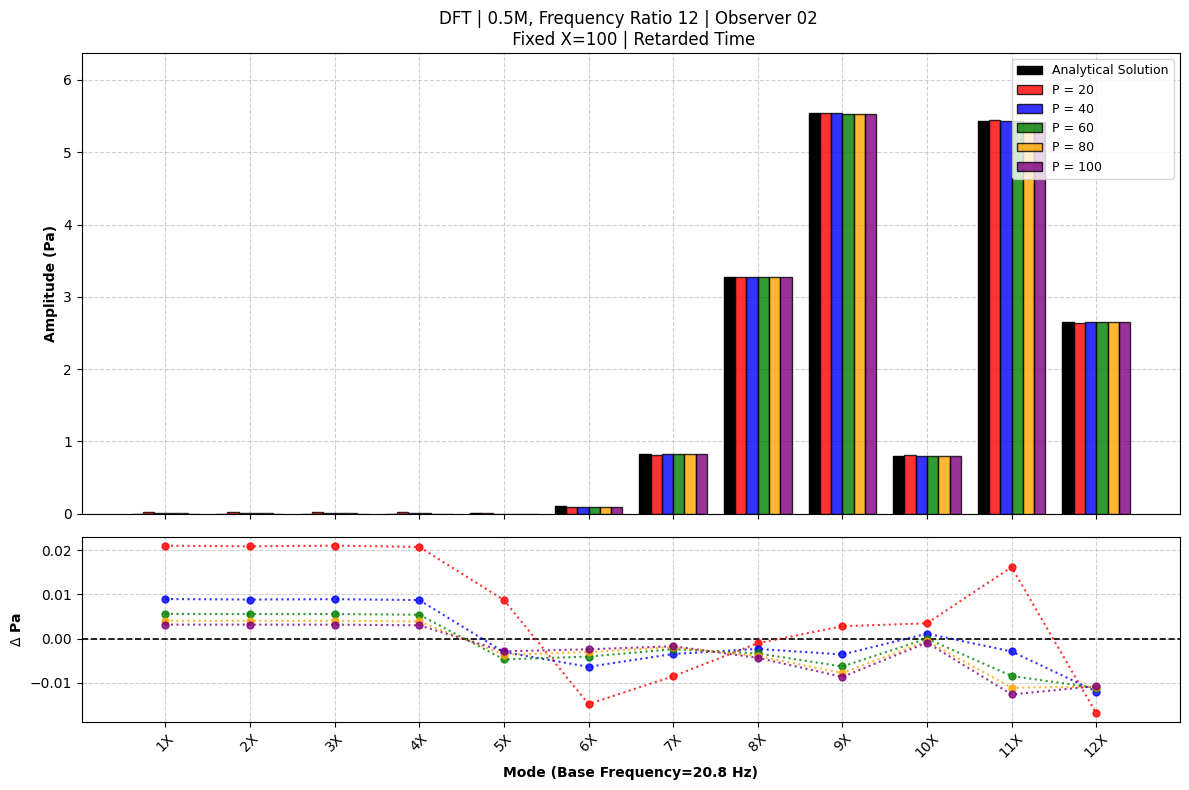

In [5]:
date = '260804'
filepath = Path(f'data_{date}/M0.5_fratio12_xpsweep')
obs_id = ['02']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 100
p_test_vals = [20, 40, 60, 80, 100, 200, 300, 400, 500]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'Pressure Time History | 0.5M, Frequency Ratio 12 | Observer {obs} \n Fixed X={x_fixed} | Retarded Time',
        error_method='l2',
        x_axis='normalised'
    )


FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 249.75
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['02']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=12', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )

FWHPlotter.plot_dft_spectrum(
    ana_dataset,
    *target_datasets,
    f_base=FWHDataset.F_SOURCE / 12,
    num_harmonics=12,
    labels=dataset_labels,
    ref_col='P_obs',
    show_error_subplot=True,
    title=f'DFT | 0.5M, Frequency Ratio 12 | Observer {obs} \n Fixed X={x_fixed} | Retarded Time',
    y_axis='Pressure'
)

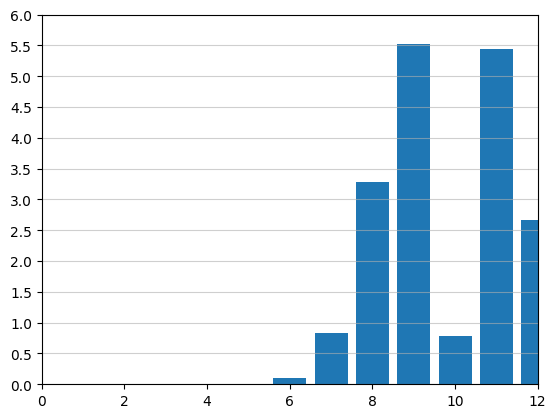

In [6]:
data = ana_dataset.data
time, pressure = data.iloc[:,0], data.iloc[:,1]

fft = np.fft.rfft(pressure)
index = range(len(fft))

fig, ax = plt.subplots()
ax.bar(index, np.abs(fft)/(len(data)) * 2)
ax.set_xlim(0, 12)
ax.set_yticks(np.linspace(0,6,13))
ax.set_ylim(0, 6)
ax.grid(True, axis='y', alpha=0.6)

In [73]:
# date = '260812'
# filepath = Path(f'data_{date}/M0.8_fratio3.0')
# obs_id = ['01']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 60
# # p_test_vals = [20, 40, 60, 80, 100]
# p_test_vals = [20, 40, 60]
# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.8M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Retarded Time',
#         error_method='l2',
#         x_axis='normalised'
#     )

# FWHDataset.R = 1.69         
# FWHDataset.C = 340.0
# FWHDataset.F_SOURCE = 99.9 
# FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
# FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

# master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# M = 0.8
# for entry in master_dataset:
#     entry['mach'] = M
#     entry['elements'] = int((2 * np.pi * FWHDataset.R * entry['X'] / ((1-M) * FWHDataset.LAMBDA_SOURCE)) **2)

# # 2. Select observers to plot
# obs_target = ['01']

# for obs in obs_target:
#     # 3. Filter the master dataset for this specific observer
#     observer_data = [d for d in master_dataset if d['observer'] == obs]
    
#     if not observer_data:
#         print(f"No data found for Observer {obs}. Skipping.")
#         continue
        
#     # 4. Pass directly to the contour plotter
#     FWHPlotter.plot_px_contour_space(
#         observer_data, 
#         add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.8, $f_{{ratio}}$=3', 
#         use_doppler=True,
#         shape_by='elements',
#         draw_mach_lines=False,
#         vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
#         vmin=1e-3               
#     )


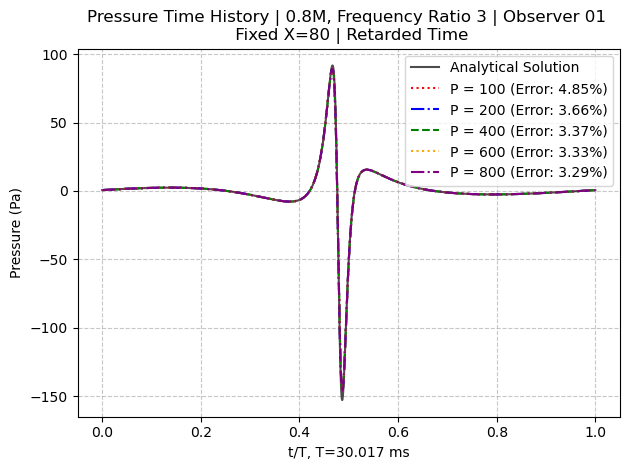

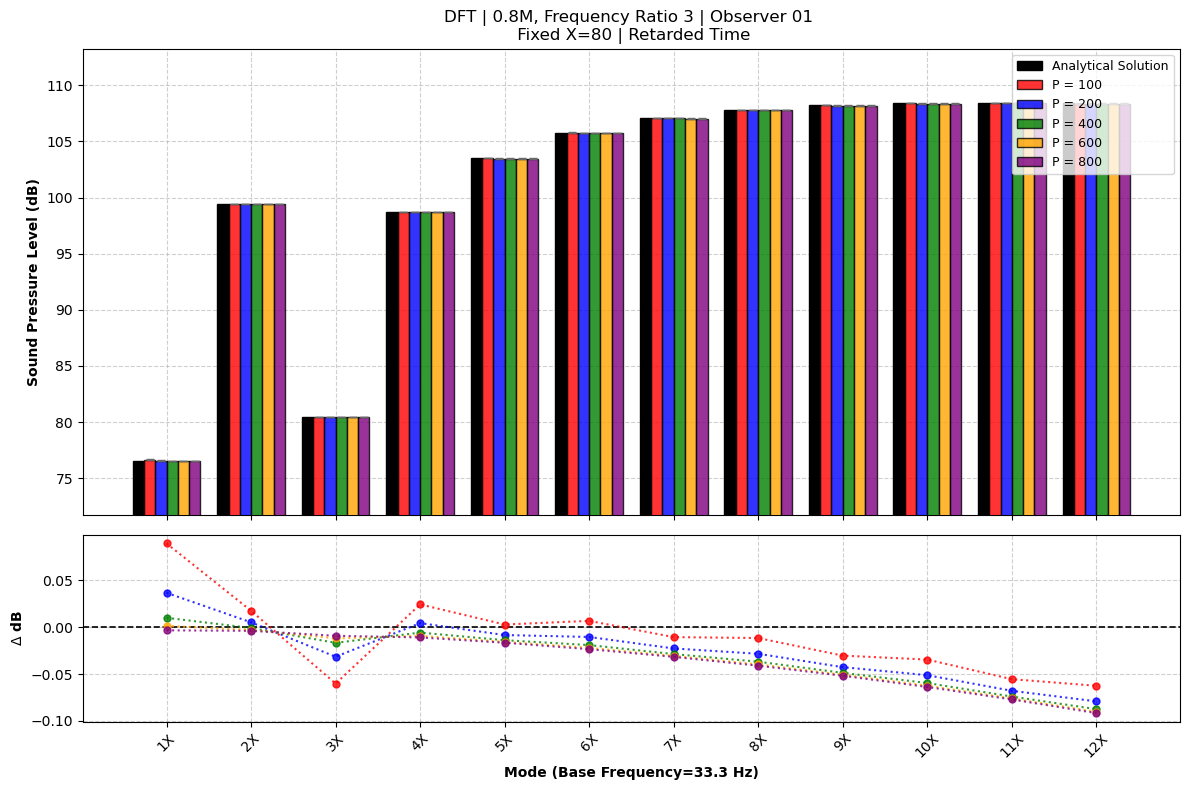

DEBUG: Loaded References: ['obs_03', 'obs_01', 'obs_02']


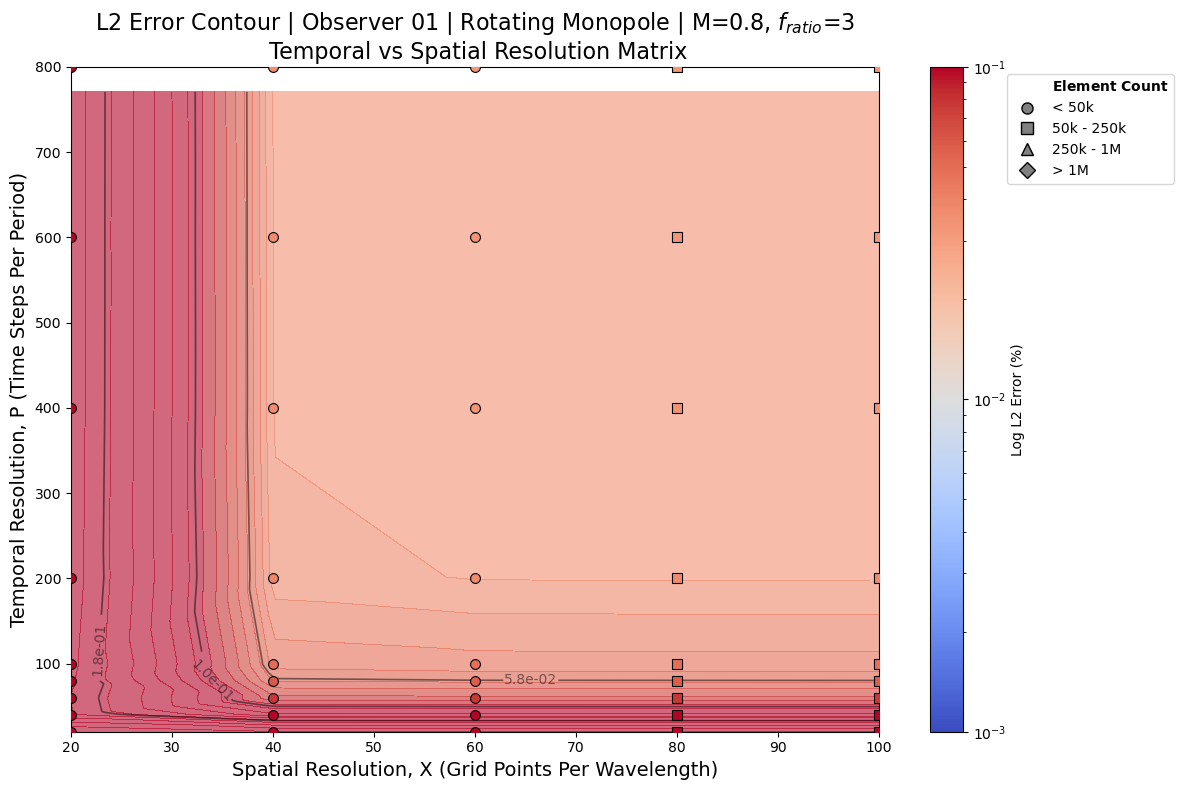

In [17]:
date = '260805'
filepath = Path(f'data_{date}/M0.8_fratio3.0')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 80
# p_test_vals = [20, 40, 60, 80, 100]
p_test_vals = [100, 200, 400, 600, 800]
for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'Pressure Time History | 0.8M, Frequency Ratio 3 | Observer {obs} \n Fixed X={x_fixed} | Retarded Time',
        error_method='l2',
        x_axis='normalised'
    )

    FWHPlotter.plot_dft_spectrum(
        ana_dataset,
        *target_datasets,
        f_base=33.3,
        num_harmonics=12,
        labels=dataset_labels,
        title=f'DFT | 0.8M, Frequency Ratio 3 | Observer {obs} \n Fixed X={x_fixed} | Retarded Time',
        ref_col='P_obs',
        show_error_bars=True,
        show_error_subplot=True,
        window='rectangular'
    )

    # FWHPlotter.plot_fft_spectrum(
    #     ana_dataset, *target_datasets, 
    #     f_base=33.3, 
    #     num_harmonics=6, 
    #     window='rectangular', 
    #     labels=dataset_labels,
    #     title=f'Interpolated Numpy FFT | 0.8M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Retarded Time',
    #     ref_col='P_obs', 
    #     show_error_subplot=True)

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 99.9
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.8, $f_{{ratio}}$=3', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )

In [37]:
# date = '260805'
# filepath = Path(f'data_{date}/M0.8_fratio3_xpsweep')
# obs_id = ['01']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 100
# p_test_vals = [20, 40, 60, 80, 100]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.8M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Retarded Time',
#         error_method='l2',
#         x_axis='normalised'
#     )

# FWHDataset.R = 1.69         
# FWHDataset.C = 340.0
# FWHDataset.F_SOURCE = 99.9
# FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
# FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

# master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# # 2. Select observers to plot
# obs_target = ['01']

# for obs in obs_target:
#     # 3. Filter the master dataset for this specific observer
#     observer_data = [d for d in master_dataset if d['observer'] == obs]
    
#     if not observer_data:
#         print(f"No data found for Observer {obs}. Skipping.")
#         continue
        
#     # 4. Pass directly to the contour plotter
#     FWHPlotter.plot_px_contour_space(
#         observer_data, 
#         add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.8, $f_{{ratio}}$=3', 
#         use_doppler=False,
#         shape_by='elements',
#         draw_mach_lines=False,
#         vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
#         vmin=1e-3               
#     )


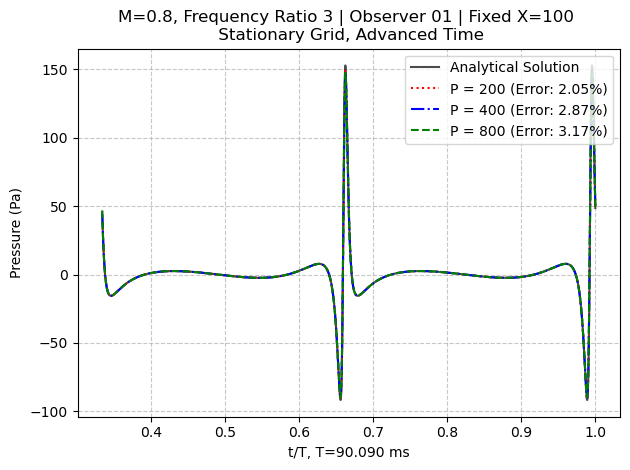

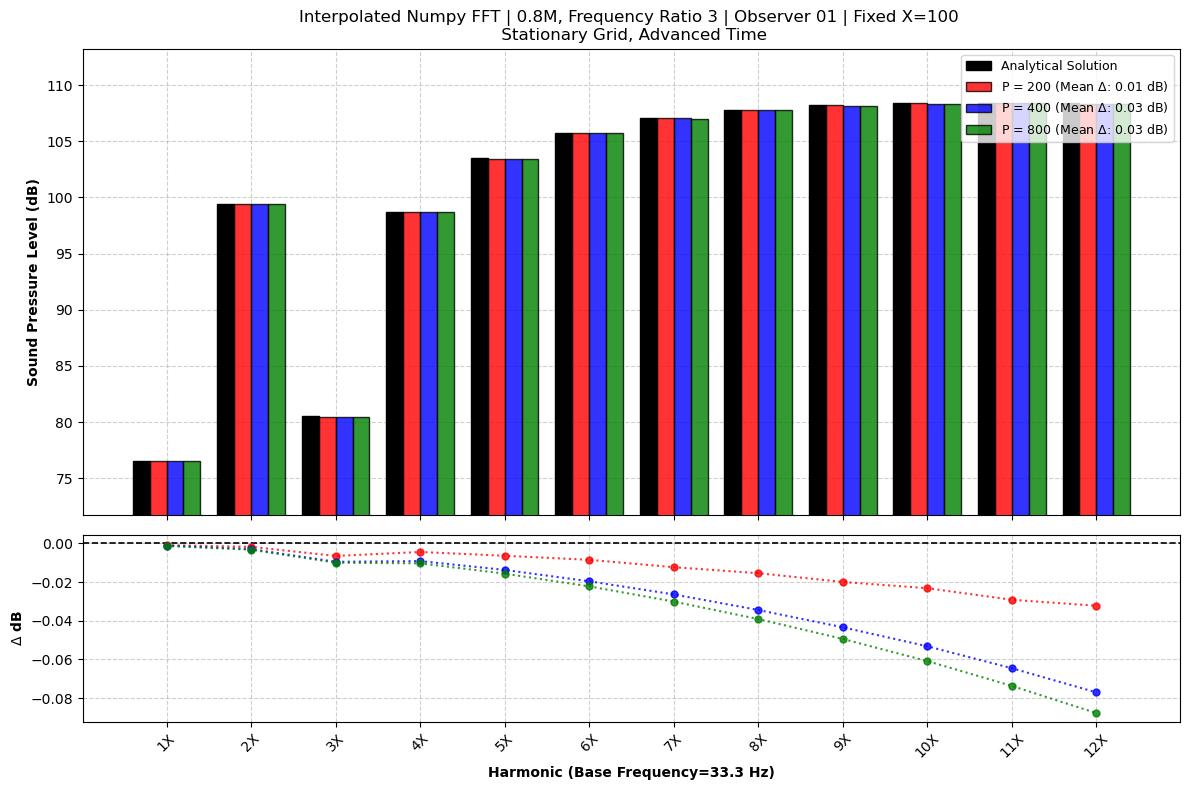

In [19]:
date = '260818'
filepath = Path(f'data_{date}/M0.8_fratio3_4rot_AT')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 100
p_test_vals = [200, 400, 800]

f_base = 33.3
T_fund = 1.0 / f_base

t_start = 1 * T_fund
t_end = 3 * T_fund

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)
    ana_mask = (ana_dataset.data['Time'] >= t_start) & (ana_dataset.data['Time'] <= t_end)
    ana_dataset.data = ana_dataset.data[ana_mask]

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            ds = FWHDataset(filepath=num_path)
            num_mask = (ds.data['Time'] >= t_start) & (ds.data['Time'] <= t_end)
            ds.data = ds.data[num_mask]
            
            target_datasets.append(ds)
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'M=0.8, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
        error_method='l2',
        x_axis='normalised',
        time_method='AT'
    )

    # FWHPlotter.plot_dft_spectrum(
    #     ana_dataset, *target_datasets, f_base=33.3, num_harmonics=6, t_start=t_start, ref_col='P_obs', comp_col='P_obs', y_axis='spl',
    #     show_error_bars=True, show_error_subplot=True, 
    #     labels=dataset_labels, title=f'Direct Integral DFT | M=0.8, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
    # )

    FWHPlotter.plot_fft_spectrum(
        ana_dataset, *target_datasets, 
        f_base=33.3, 
        num_harmonics=12, 
        window='rectangular',
        t_start=t_start, t_end=t_end,
        labels=dataset_labels,
        title=f'Interpolated Numpy FFT | 0.8M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
        ref_col='P_obs', 
        show_error_subplot=True)


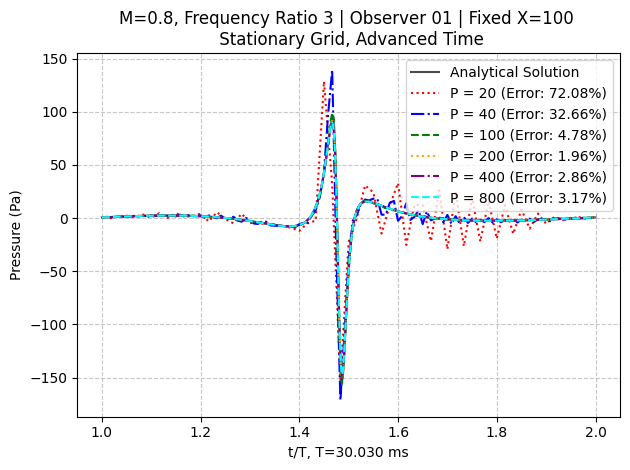

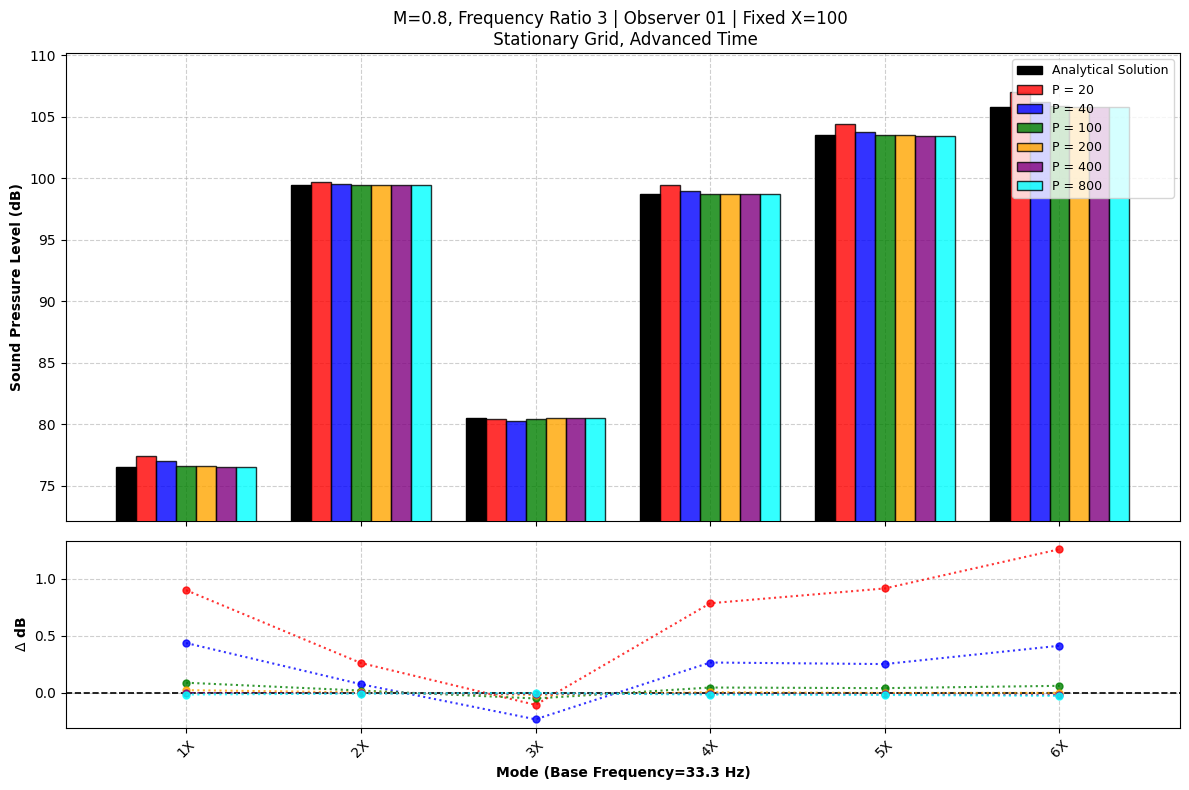

In [39]:
date = '260817'
filepath = Path(f'data_{date}/M0.8_fratio3_2rot_AT')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 100
p_test_vals = [20, 40, 100, 200, 400, 800]
# p_test_vals = [100, 200, 400, 600, 800]

f_base = 33.3
T_base = 1 / f_base
t_start = 1 * T_base
t_end = 2 * T_base

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)
    ana_mask = (ana_dataset.data['Time'] >= t_start) & (ana_dataset.data['Time'] <= t_end)
    ana_dataset.data = ana_dataset.data[ana_mask]

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():

            ds = FWHDataset(filepath=num_path)
            num_mask = (ds.data['Time'] >= t_start) & (ds.data['Time'] <= t_end)
            ds.data = ds.data[num_mask]
            
            target_datasets.append(ds)
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'M=0.8, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
        error_method='l2',
        x_axis='normalised',
        time_method='AT',
        time_period=T_base
    )

    FWHPlotter.plot_dft_spectrum(
        ana_dataset, *target_datasets, ref_col='P_obs', labels=dataset_labels, title=f'M=0.8, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
        f_base=f_base, num_harmonics=6, show_error_subplot=True
    )

    # FWHPlotter.plot_fft_spectrum(
    #     ana_dataset, *target_datasets, 
    #     f_base=f_base, 
    #     num_harmonics=6, 
    #     window='rectangular',
    #     t_start=t_start, t_end=t_end,
    #     labels=dataset_labels,
    #     title=f'Interpolated Numpy FFT | M=0.8, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
    #     ref_col='P_obs', 
    #     show_error_subplot=True)


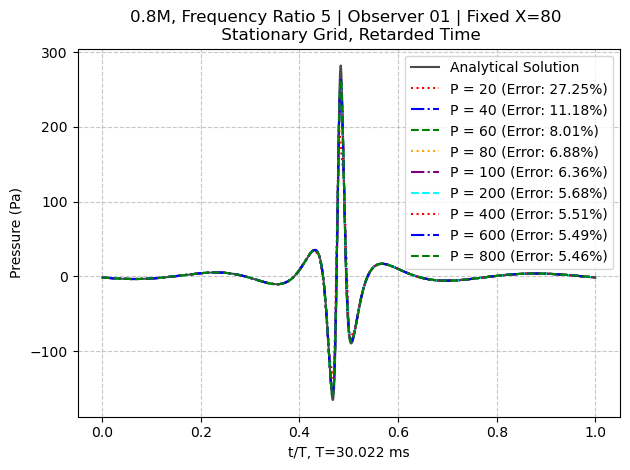

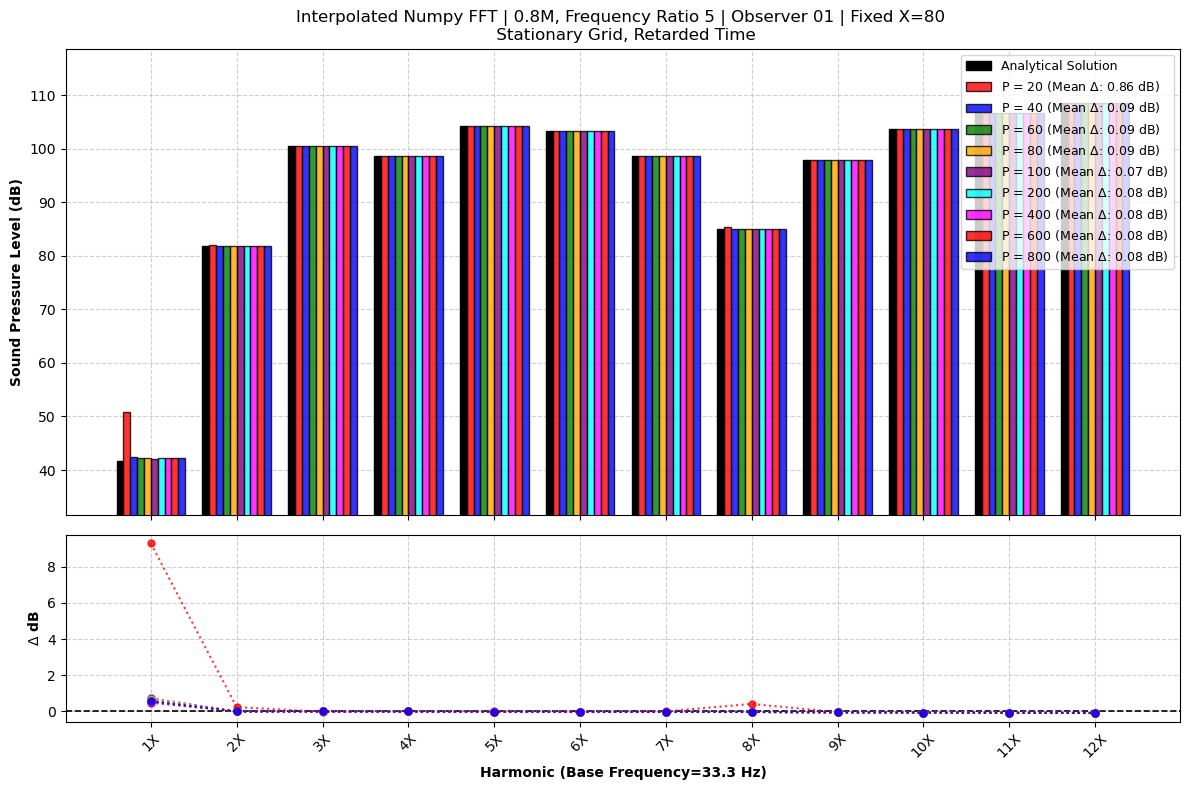

DEBUG: Loaded References: ['obs_01', 'obs_03', 'obs_02']


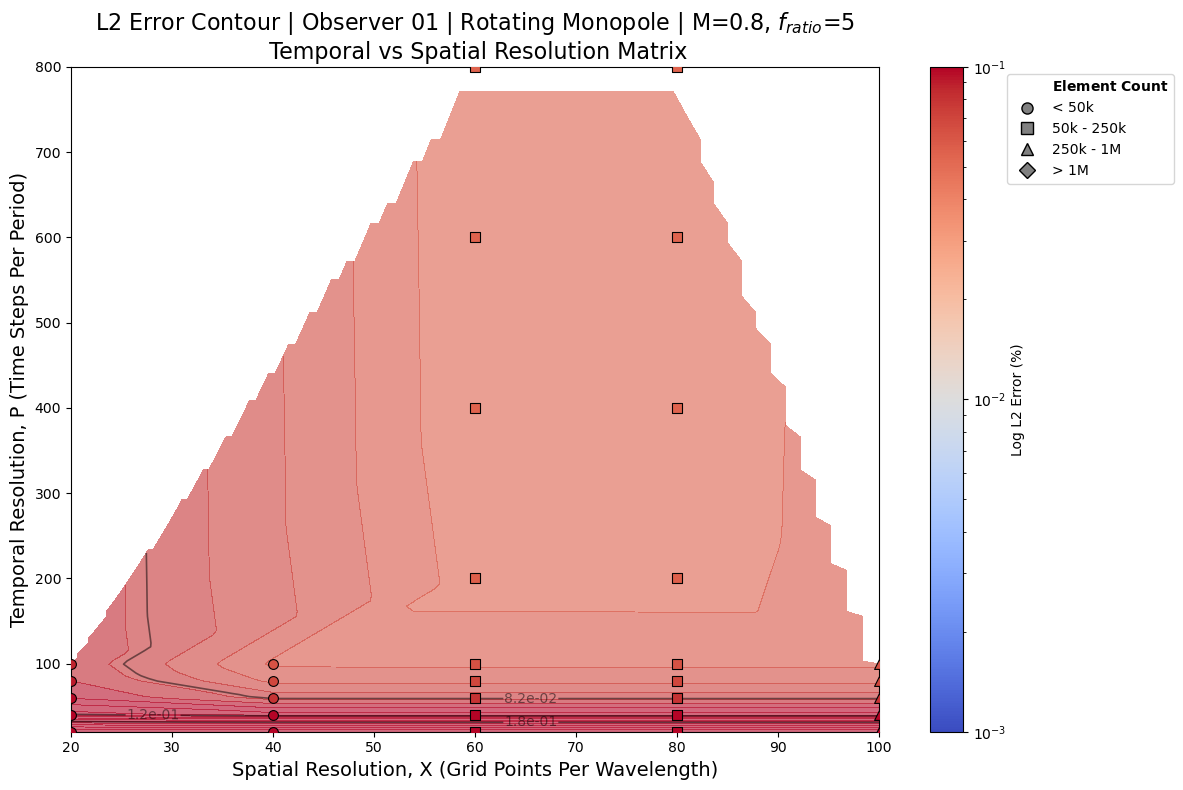

In [20]:
date = '260806'
filepath = Path(f'data_{date}/M0.8_fratio5')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 80
p_test_vals = [20, 40, 60, 80, 100, 200, 400, 600, 800]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.8M, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Retarded Time',
        error_method='l2',
        x_axis='normalised'
    )

    # FWHPlotter.plot_dft_spectrum(
    #     ana_dataset,
    #     *target_datasets,
    #     f_base=33.3,
    #     num_harmonics=5,
    #     labels=dataset_labels,
    #     title=f'Direct Integral DFT | 0.8M, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Retarded Time',
    #     ref_col='P_obs',
    #     show_error_bars=True,
    #     show_error_subplot=True
    # )

    FWHPlotter.plot_fft_spectrum(
        ana_dataset, *target_datasets, 
        f_base=33.3, 
        num_harmonics=12, 
        window='rectangular', 
        labels=dataset_labels,
        title=f'Interpolated Numpy FFT | 0.8M, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Retarded Time',
        ref_col='P_obs', 
        show_error_subplot=True)
    

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 166.5
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.8, $f_{{ratio}}$=5', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


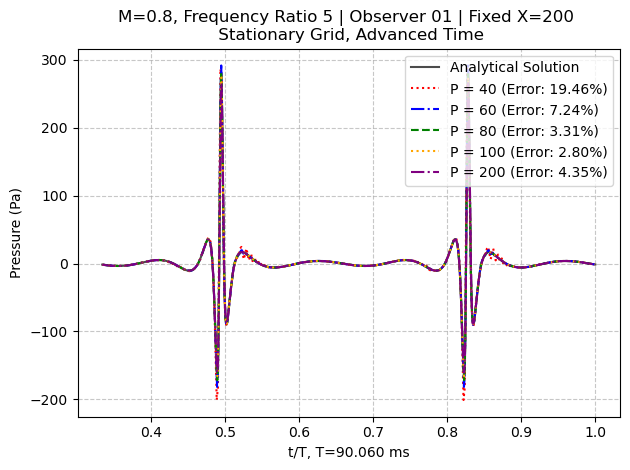

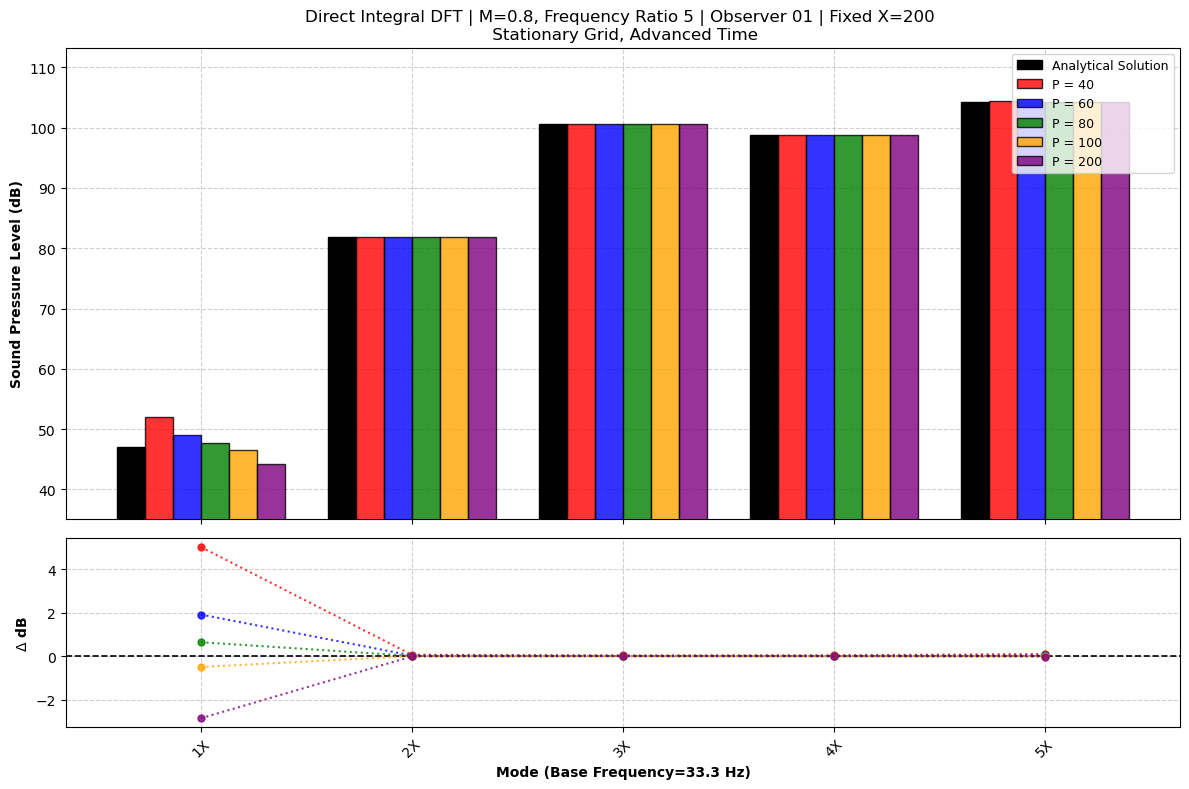

DEBUG: Loaded References: ['obs_01', 'obs_03', 'obs_02']


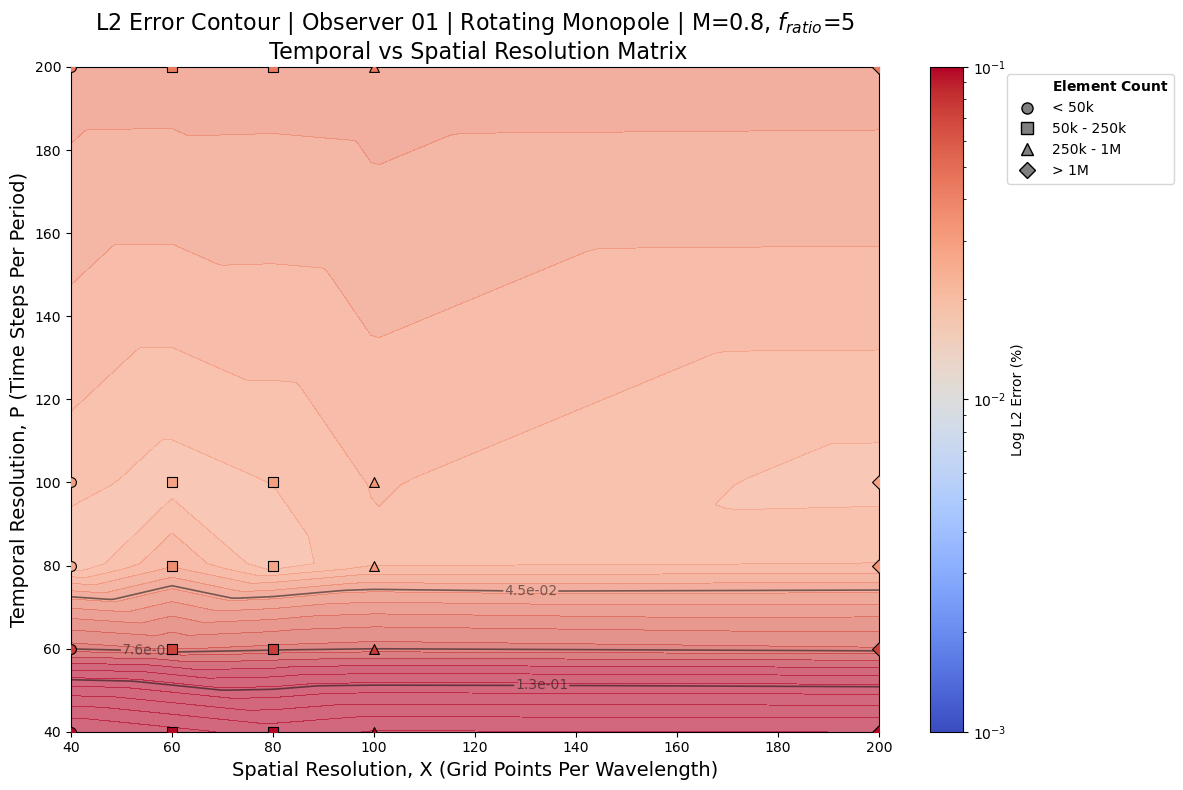

In [21]:
date = '260819'
filepath = Path(f'data_{date}/M0.8_fratio5_AT')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 200
p_test_vals = [20, 40, 60, 80, 100, 200, 400, 600, 800]

f_base = 33.3
T_base = 1 / f_base
t_start = 1 * T_base
t_end = 3 * T_base

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)
    ana_mask = (ana_dataset.data['Time'] >= t_start) & (ana_dataset.data['Time'] <= t_end)
    ana_dataset.data = ana_dataset.data[ana_mask]

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():

            ds = FWHDataset(filepath=num_path)
            num_mask = (ds.data['Time'] >= t_start) & (ds.data['Time'] <= t_end)
            ds.data = ds.data[num_mask]
            
            target_datasets.append(ds)
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'M=0.8, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
        error_method='l2',
        x_axis='normalised',
        time_method='AT'
    )

    FWHPlotter.plot_dft_spectrum(
        ana_dataset, *target_datasets, ref_col='P_obs', labels=dataset_labels, title=f'Direct Integral DFT | M=0.8, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
        f_base=f_base, num_harmonics=5, show_error_subplot=True
    )

    # FWHPlotter.plot_fft_spectrum(
    #     ana_dataset, *target_datasets, ref_col='P_obs', labels=dataset_labels, title=f'Interpolated NumPy FFT | M=0.8, Frequency Ratio 5 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Advanced Time',
    #     f_base=f_base, num_harmonics=5, show_error_subplot=True
    # )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 166.5
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True, t_start=t_start, t_end=t_end,)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.8, $f_{{ratio}}$=5', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


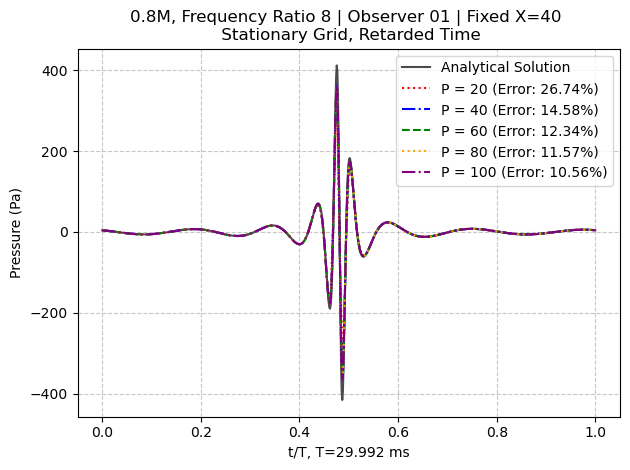

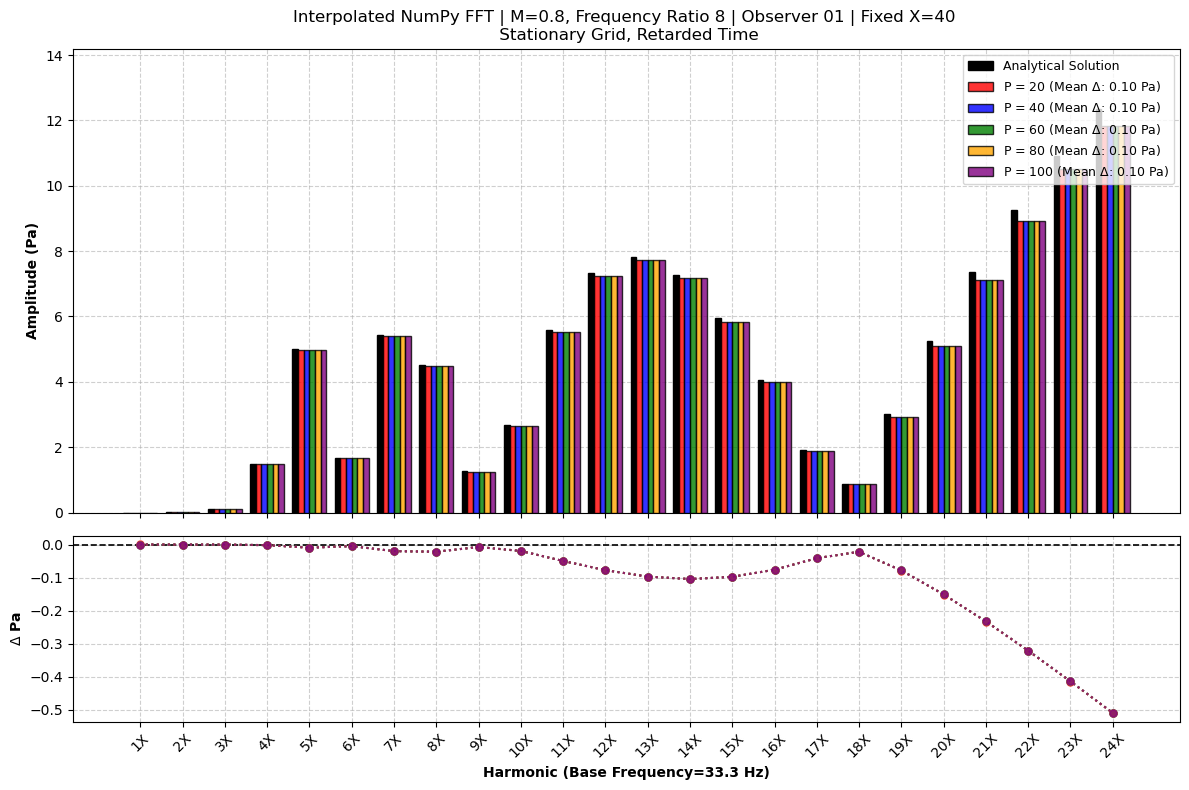

DEBUG: Loaded References: ['obs_01', 'obs_03', 'obs_02']


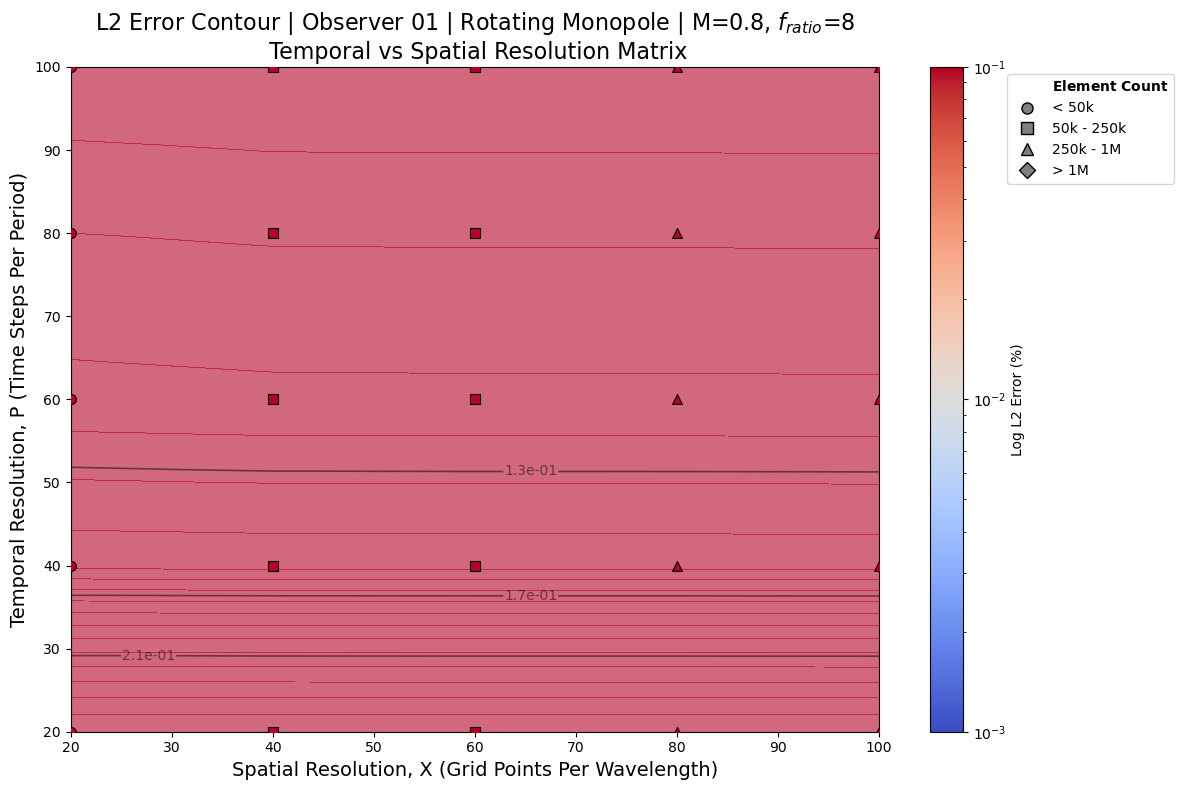

In [27]:
date = '260806'
filepath = Path(f'data_{date}/M0.8_fratio8')
obs_id = ['01']   # Select target observer

# ==========================================
# 1. Temporal Convergence (Fixed X, Varying P)
# ==========================================
x_fixed = 40
p_test_vals = [20, 40, 60, 80, 100]

for obs in obs_id:
    ana_path = filepath / f'ana_spatial_{obs}.dat'
    ana_dataset = FWHDataset(filepath=ana_path)

    target_datasets = []
    dataset_labels = []

    for p in p_test_vals:
        num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
        if num_path.exists():
            target_datasets.append(FWHDataset(filepath=num_path))
            dataset_labels.append(f'P = {p}')

    FWHPlotter.plot_pressure(
        ana_dataset, 
        *target_datasets, 
        ref_col='P_obs',
        labels=dataset_labels,
        title=f'0.8M, Frequency Ratio 8 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Retarded Time',
        error_method='l2',
        x_axis='normalised'
    )

    # FWHPlotter.plot_dft_spectrum(
    #     ana_dataset, *target_datasets, ref_col='P_obs', labels=dataset_labels, title=f'Direct Integral DFT | M=0.8, Frequency Ratio 8 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Retarded Time',
    #     f_base=f_base, num_harmonics=8, show_error_subplot=True
    # )

    FWHPlotter.plot_fft_spectrum(
        ana_dataset, *target_datasets, ref_col='P_obs', labels=dataset_labels, title=f'Interpolated NumPy FFT | M=0.8, Frequency Ratio 8 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Retarded Time',
        f_base=f_base, num_harmonics=24, show_error_subplot=True, window='rectangular', y_axis='pressure'
    )

FWHDataset.R = 1.69         
FWHDataset.C = 340.0
FWHDataset.F_SOURCE = 266.4
FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# 2. Select observers to plot
obs_target = ['01']

for obs in obs_target:
    # 3. Filter the master dataset for this specific observer
    observer_data = [d for d in master_dataset if d['observer'] == obs]
    
    if not observer_data:
        print(f"No data found for Observer {obs}. Skipping.")
        continue
        
    # 4. Pass directly to the contour plotter
    FWHPlotter.plot_px_contour_space(
        observer_data, 
        add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.8, $f_{{ratio}}$=8', 
        use_doppler=False,
        shape_by='elements',
        draw_mach_lines=False,
        vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
        vmin=1e-3               
    )


In [13]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio12_xpsweep')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 60
# p_test_vals = [20, 40, 60, 80, 100]

# for obs in obs_id:
#     # ana_path = filepath / f'ana_spatial_{obs}.dat'
#     # ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         # ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Fixed Monopole Pressure, Non-Doppler Shifted Resolution',
#         error_method='l2',
#         x_axis='normalised'
#     )

# FWHDataset.R = 1.69         
# FWHDataset.C = 340.0
# FWHDataset.F_SOURCE = 99.9
# FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
# FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

# master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# # 2. Select observers to plot
# obs_target = ['01']

# for obs in obs_target:
#     # 3. Filter the master dataset for this specific observer
#     observer_data = [d for d in master_dataset if d['observer'] == obs]
    
#     if not observer_data:
#         print(f"No data found for Observer {obs}. Skipping.")
#         continue
        
#     # 4. Pass directly to the contour plotter
#     FWHPlotter.plot_px_contour_space(
#         observer_data, 
#         add_title=f'L2 Error Contour | Observer {obs} | Rotating Monopole | M=0.5, $f_{{ratio}}$=5', 
#         use_doppler=False,
#         shape_by='elements',
#         draw_mach_lines=False,
#         vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
#         vmin=1e-3               
#     )


In [9]:
# date = '260728'
# filepath = Path(f'data_{date}/M08_fratio12')
# obs_id = ['01','02','03']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 100
# p_test_vals = [100]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Pressure Time History | Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         # x_axis='normalised'
#     )


In [10]:
# FWHDataset.R = 1.69         
# FWHDataset.C = 340.0
# FWHDataset.F_SOURCE = 400
# FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
# FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

# master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# # 2. Select observers to plot
# obs_target = ['01']

# for obs in obs_target:
#     # 3. Filter the master dataset for this specific observer
#     observer_data = [d for d in master_dataset if d['observer'] == obs]
    
#     if not observer_data:
#         print(f"No data found for Observer {obs}. Skipping.")
#         continue
        
#     # 4. Pass directly to the contour plotter
#     FWHPlotter.plot_px_contour_space(
#         observer_data, 
#         add_title=f'L2 Error Contour | Observer {obs} | Multipole Validation', 
#         use_doppler=False,
#         shape_by='elements',
#         draw_mach_lines=False,
#         vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
#         vmin=1e-3               
#     )


In [11]:
# date = '260729'
# filepath = Path(f'data_{date}/M08_fratio8')
# obs_id = ['01']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 100
# p_test_vals = [20, 40, 60, 80, 100]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'Pressure Time History | Observer {obs} | Fixed X={x_fixed}',
#         error_method='l2',
#         # x_axis='normalised'
#     )


In [12]:
# FWHDataset.R = 1.69         
# FWHDataset.C = 340.0
# FWHDataset.F_SOURCE = 400 * 2 / 3
# FWHDataset.OMEGA = FWHDataset.F_SOURCE * 2 * np.pi
# FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE

# master_dataset = FWHDataset.compile_fwh_batch(filepath, use_doppler=False, verbose=True)

# # 2. Select observers to plot
# obs_target = ['01']

# for obs in obs_target:
#     # 3. Filter the master dataset for this specific observer
#     observer_data = [d for d in master_dataset if d['observer'] == obs]
    
#     if not observer_data:
#         print(f"No data found for Observer {obs}. Skipping.")
#         continue
        
#     # 4. Pass directly to the contour plotter
#     FWHPlotter.plot_px_contour_space(
#         observer_data, 
#         add_title=f'L2 Error Contour | Observer {obs} | Multipole Validation', 
#         use_doppler=False,
#         shape_by='elements',
#         draw_mach_lines=False,
#         vmax=1e-1, # Leave None initially to prevent clipping if errors are outside bounds
#         vmin=1e-3               
#     )


In [ ]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio3_newanalytical_stationary_freestream')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Monopole Fix, Freestream X',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio3_newanalytical_stationarygrid')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid, Monopole Fix, Doppler-shifted X',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio3_newanalytical_doppler')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Rotating Grid, Monopole Fix, Doppler-shifted X',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260803'
# filepath = Path(f'data_{date}/M05_fratio3_dopplershifted')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Doppler-shifted Resolutions, Rotating Grid',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260804'
# filepath = Path(f'data_{date}/M0.5_fratio3_newanalytical')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Rotating Grid, Monopole Fix',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260803'
# filepath = Path(f'data_{date}/M05_fratio3_rotatinggrid')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Rotating Grid',
#         error_method='l2',
#         x_axis='normalised'
#     )


In [ ]:
# date = '260803'
# filepath = Path(f'data_{date}/M05_fratio3')
# obs_id = ['02']   # Select target observer

# # ==========================================
# # 1. Temporal Convergence (Fixed X, Varying P)
# # ==========================================
# x_fixed = 80
# p_test_vals = [20, 40, 60, 80]

# for obs in obs_id:
#     ana_path = filepath / f'ana_spatial_{obs}.dat'
#     ana_dataset = FWHDataset(filepath=ana_path)

#     target_datasets = []
#     dataset_labels = []

#     for p in p_test_vals:
#         num_path = filepath / f'X{x_fixed}_P{p}_{obs}.dat'
#         if num_path.exists():
#             target_datasets.append(FWHDataset(filepath=num_path))
#             dataset_labels.append(f'P = {p}')

#     FWHPlotter.plot_pressure(
#         ana_dataset, 
#         *target_datasets, 
#         ref_col='P_obs',
#         labels=dataset_labels,
#         title=f'0.5M, Frequency Ratio 3 | Observer {obs} | Fixed X={x_fixed} \n Stationary Grid',
#         error_method='l2',
#         x_axis='normalised'
#     )
